In [1]:
import bilby
import h5py

In [2]:
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams['font.family'] = 'Times New Roman'
matplotlib.rcParams['font.sans-serif'] = ['Bitstream Vera Sans']
matplotlib.rcParams['text.usetex'] = True
matplotlib.rcParams['mathtext.fontset'] = 'cm'
matplotlib.rcParams['axes.unicode_minus'] = False

import seaborn as sns
sns.set_context('talk')
sns.set_style('ticks')
sns.set_palette('colorblind')
colors=sns.color_palette('colorblind')
fs=80



In [3]:
import matplotlib as mpl
mpl.rcParams['axes.unicode_minus'] = False

# 2) Use a font family that *definitely* has the ASCII minus
mpl.rcParams['font.family'] = 'DejaVu Sans'

# 3) Make sure mathtext also uses DejaVu fonts (not "default")
mpl.rcParams['mathtext.fontset'] = 'dejavusans'
mpl.rcParams['mathtext.default'] = 'regular'

# 4) Make sure we're *not* going through TeX
mpl.rcParams['text.usetex'] = False
# Display plots

In [4]:
%matplotlib inline

In [5]:
%load_ext autoreload
%autoreload 2

In [6]:
from popsummary import popresult

In [7]:
import sys
sys.path.append("src/")

In [8]:
# result = bilby.read_in_result("results/gwtc4_mixture_mixz_gaussianchipall_correct_znorm_result.hdf5")
result = bilby.read_in_result("results/gwtc5_mixture_result.hdf5")

In [9]:
result.posterior

,alpha11,alpha31,alpha32,alpha_21,alpha_22,break_mass2,break_mass3,delta_m,lam1,lamb_1,...,q_sigma3,sigma_chi_eff1,sigma_chi_eff2,sigma_chi_p1,sigma_chi_p2,sigma_chi_p3,sigpp1,w_1,w_23,w_chi_eff3
0,2.378571,2.237115,5.467393,-0.178082,22.601152,39.746219,77.927399,9.398489,0.324956,1.504587,...,0.126003,0.067495,0.076728,0.095181,0.883768,0.345643,1.803826,0.783641,0.752235,0.542216
1,1.467446,3.229911,2.524631,-1.572670,17.971186,39.324763,64.981175,2.503648,0.566492,-0.300993,...,0.184904,0.083584,0.123177,0.120277,0.272960,0.128245,1.007088,0.871265,0.473973,0.488742
2,2.738309,2.710912,3.478483,-0.755757,10.530861,36.578181,54.504734,3.118508,0.511663,4.110198,...,0.189284,0.085139,0.064513,0.093300,0.221293,0.290500,2.572723,0.640265,0.831812,0.502133
3,1.912010,2.920615,2.466529,-1.429375,12.089540,36.781957,43.246551,5.381087,0.705534,1.295680,...,0.172640,0.077471,0.134671,0.107874,0.231344,0.578271,2.521624,0.830190,0.599195,0.579795
4,2.142011,3.131826,2.534096,-2.145387,13.851522,34.710582,33.973876,7.403903,0.428405,1.862571,...,0.148977,0.098744,0.122267,0.117378,0.237270,0.279574,1.450265,0.935179,0.671994,0.608253
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4965,2.601201,2.131782,4.604062,-3.962847,13.379572,35.024122,60.092183,1.224515,0.461076,2.191141,...,0.163831,0.060994,0.092973,0.141643,0.233956,0.167866,0.753863,0.813652,0.604939,0.495961
4966,2.581183,2.681608,4.763446,-3.799371,10.071634,34.653974,59.509630,0.398631,0.562497,1.368585,...,0.162756,0.067748,0.080110,0.104244,0.225081,0.172051,0.948828,0.761754,0.630127,0.474924
4967,2.623473,2.922020,5.445084,-3.238754,9.648350,33.694612,65.458153,1.665931,0.532006,2.511338,...,0.150424,0.062798,0.084860,0.146920,0.193047,0.156847,0.791196,0.749502,0.695193,0.472696
4968,2.742484,2.514389,6.357743,-1.671797,11.497483,35.285954,63.738012,2.964772,0.480507,0.861861,...,0.200392,0.066631,0.089942,0.126292,0.197268,0.170006,0.875427,0.817018,0.568426,0.511657


In [10]:
# result2 = bilby.read_in_result("results/gwtc4_default_result.hdf5")
result2 = bilby.read_in_result("results/gwtc5_default_result.hdf5")

In [11]:
result.log_10_bayes_factor - result2.log_10_bayes_factor

np.float64(10.02725000321243)

In [12]:
result.log_bayes_factor-result2.log_bayes_factor

np.float64(23.088596381120624)

In [13]:
posterior = result.posterior

In [14]:
posterior.keys()

Index(['alpha11', 'alpha31', 'alpha32', 'alpha_21', 'alpha_22', 'break_mass2',
       'break_mass3', 'delta_m', 'lam1', 'lamb_1', 'lamb_2', 'lamb_3',
       'log_likelihood', 'log_prior', 'm2min', 'mmax1', 'mmin1', 'mmin3',
       'mpp1', 'mu_chi_eff1', 'mu_chi_eff2', 'mu_chi_p1', 'mu_chi_p2',
       'mu_chi_p3', 'q_beta2', 'q_epsilon1', 'q_mu1', 'q_mu3', 'q_sigma1',
       'q_sigma3', 'sigma_chi_eff1', 'sigma_chi_eff2', 'sigma_chi_p1',
       'sigma_chi_p2', 'sigma_chi_p3', 'sigpp1', 'w_1', 'w_23', 'w_chi_eff3'],
      dtype='object')

In [15]:
plot_dir = "plots_o4b"
# plot_dir = "plots"
fs=70
hist_lw = 3.5

### PISN

In [16]:
from scipy.stats import gaussian_kde

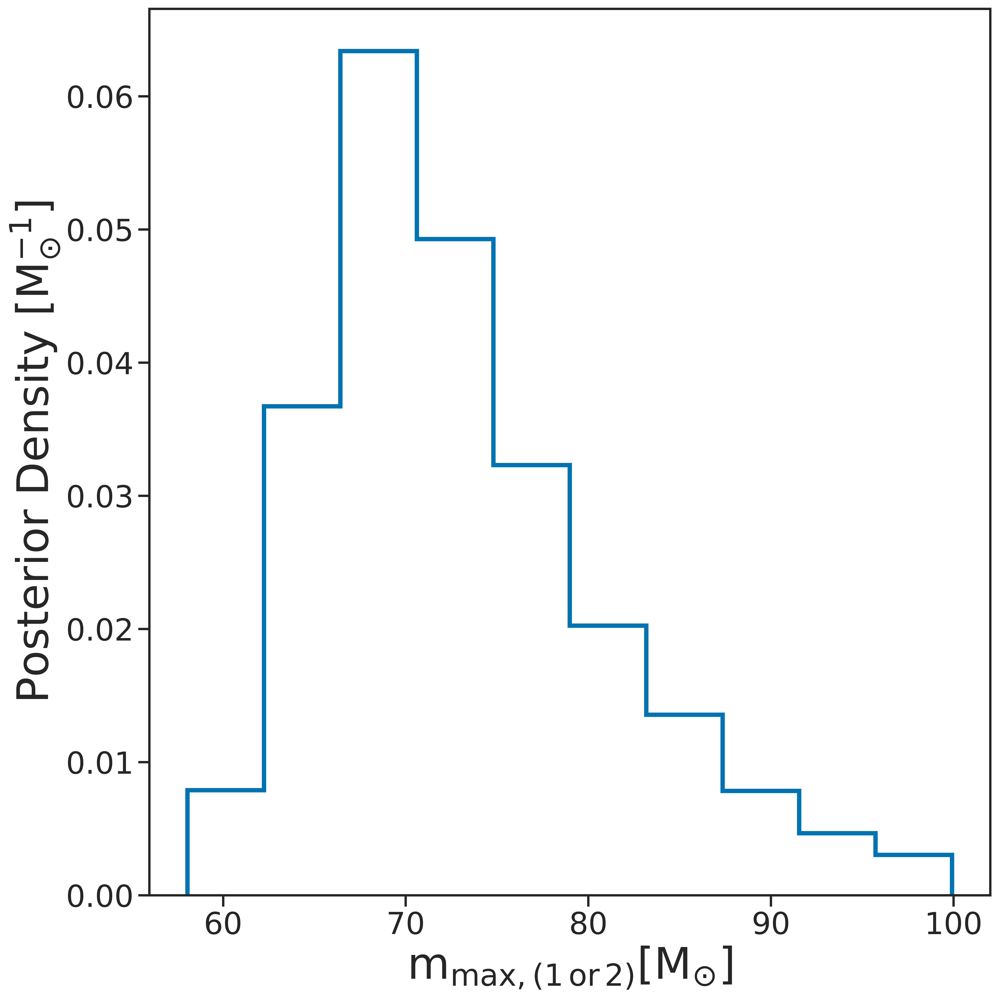

In [17]:
fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})
_=ax.hist(posterior["mmax1"].to_numpy(), density=True, histtype = "step", rasterized=True, lw = hist_lw)
ax.set_xlabel(r"$m_{max,(1\,or\,2)}[M_{\odot}]$", fontsize = tfs)
ax.set_ylabel(r"Posterior Density $[M_{\odot}^{-1}]$", fontsize = tfs)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
fig.tight_layout()
fig.savefig(f'{plot_dir}/mmax1.png')
fig.savefig(f'{plot_dir}/mmax1.pdf')
plt.show()

#### Farmer 2020

In [18]:
#masses=np.array(np.arange(30,200,2))
import numpy as np
bases_c12_rate = ['m30','m25','m20','m15','m10','m05','p00','p05','p10','p15','p20','p25','p30']
labelsc12_rate = ['-3','-2.5','-2.0','-1.5','-1.0','-0.5','0.0','0.5','1.0','1.5','2.0','2.5','3.0']

bases_others = ['cf88','deboer','deboer_m','deboer_p','jina','kunz','nacre']
labels_others = bases_others

bases_high = ['3alow1s_h','3ahigh1s_h','o16high_h','o16low_h','tum_h_h','tum_l_h','tum_m_h']
labels_high = bases_high

bases_low = ['3alow1s_l','3ahigh1s_l','o16high_l','o16low_l','tum_h_l','tum_l_l','tum_m_l']
labels_low = bases_low

bases_mid = ['3alow1s_m','3ahigh1s_m','o16high_m','o16low_m','tum_h_m','tum_l_m','tum_m_m']
labels_mid = bases_mid

bases_split = ['corehe','shellhe','exphe']
labels_split = bases_split


masses = np.arange(30,201,1)
masses = np.array([round(i,1) for i in masses])

G=6.67428*10**-8
msun=1.9892*10**33
rsun=6.9598*10**10

data = np.genfromtxt('/home/anarya.ray/noPISN/repo/nopisn//Farmer_2020/data/all_models.txt',names=True,dtype=None,encoding=None) 

In [19]:
sigmas=[-3,-2.5,-2,-1.5,-1,-0.5,0.0,0.5,1.0,1.5,2.0,2.5,3.0]

mbh = []
ind=np.logical_or(data['symbol']==3.0,data['symbol']==2)&(data['bhmass'] < 110.0)
for i in bases_c12_rate:
    ind2=(data['base']==i)&ind
    mbh.append(np.nanmax(data['bhmass'][ind2]))
    
#print(mbh)

bh2sig=np.poly1d(np.polyfit(mbh,sigmas,deg=4))

In [20]:
# Map sigma to rate
import os
def sig2rate(filename):
    def loadfile(filename):
        return np.genfromtxt(filename,names=["t8",'rate'],dtype=None,skip_header=3)
    base=loadfile('/home/anarya.ray/noPISN/repo/nopisn/Farmer_2020/input/rates/c12alpha/p00/rate_tables/rate.txt')
    x=loadfile(os.path.join('/home/anarya.ray/noPISN/repo/nopisn//Farmer_2020/input/rates/c12alpha',filename,'rate_tables','rate.txt'))
    xx=x['t8']/10.0
    yy=x['rate']/base['rate']
    ind = np.nanargmin(np.abs(xx-0.3))
    return yy[ind]

In [21]:
allrates=[]
for i in bases_c12_rate:
    j=sig2rate(i)
    allrates.append(j)
    
fitsig2rate=np.poly1d(np.polyfit([float(i) for i in labelsc12_rate],allrates,deg=2))

/tmp/ipykernel_1896/2538320055.py:9: RuntimeWarning: invalid value encountered in divide
  yy=x['rate']/base['rate']


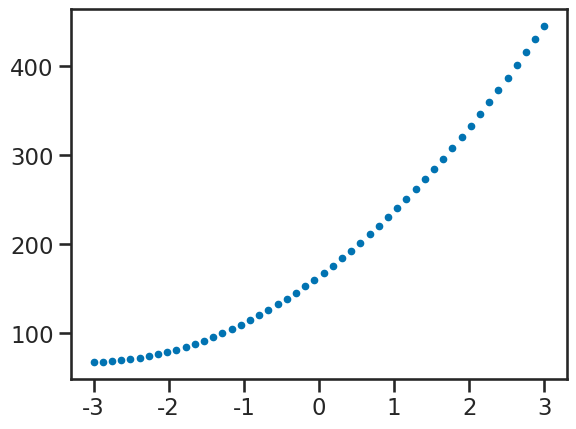

In [22]:
plt.plot(np.linspace(-3,3), fitsig2rate(np.linspace(-3,3)) * 165, '.')

In [23]:
rate_spin_gap = fitsig2rate(bh2sig(posterior["mmax1"].to_numpy())) * 165
#print(rate_spin_gap_range)
rate_spin_gap_range = rate_spin_gap[rate_spin_gap<1000]
from scipy.stats import gaussian_kde
from scipy.integrate import cumulative_trapezoid as cumtrapz
from scipy.interpolate import interp1d
#print(rate_spin_gap_range)
kde = gaussian_kde(rate_spin_gap_range)
s_range = np.logspace(-3,3, 10000)
pdf = kde(s_range)
pdf/=np.trapz(pdf, s_range)
cdf = cumtrapz(pdf, s_range, initial = 0.0)
cdf/=cdf[-1]
icdf = interp1d(cdf, s_range)
print(icdf(0.5), icdf(0.5)-icdf(0.05),icdf(0.95)-icdf(0.5))

84.53339560916632 14.420456797247454 5.132725338071779


/tmp/ipykernel_1896/2793481563.py:11: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pdf/=np.trapz(pdf, s_range)


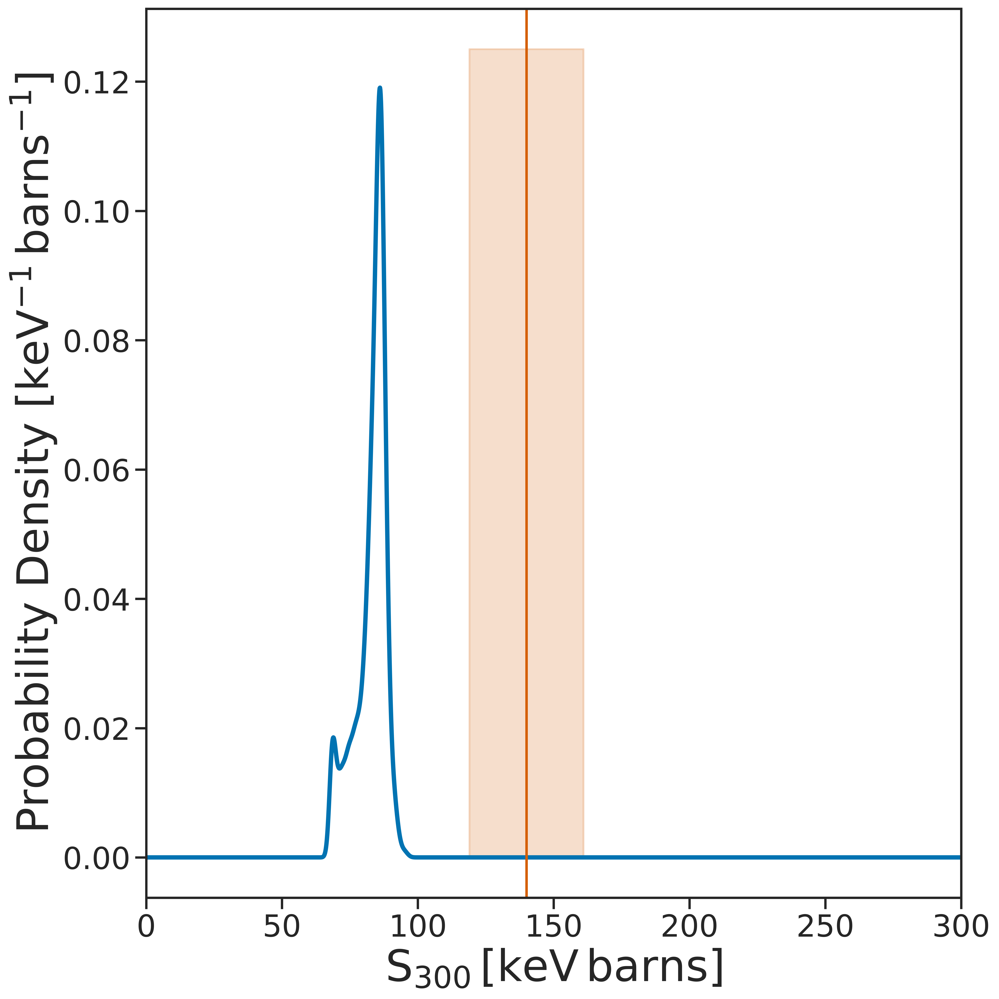

In [24]:
fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})
_=ax.plot(s_range, pdf, rasterized=True, lw = hist_lw)
ax.axvline(140,label='deBoer 2017',color=sns.color_palette()[3], linewidth=2.0)
ax.fill_betweenx([0,max(pdf)*1.05],140-21,140+21,color=sns.color_palette()[3],alpha=0.2)
ax.set_xlabel(r'$S_{300}\,[\rm{keV\,barns}]$', fontsize = tfs)
ax.set_ylabel(r'Probability Density [$\rm{keV^{-1}\,barns^{-1}}$]', fontsize = tfs)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
ax.set_xlim(0,300)
fig.tight_layout()
fig.savefig(f'{plot_dir}/S300_Farmer.png')
fig.savefig(f'{plot_dir}/S300_Farmer.pdf')
plt.show()

#### Farag 2023

In [25]:
import numpy as np
sigma= [-3,
-2.5,
-2,
-1.5,
-1,
-0.5,
0,
0.5,
1,
1.5,
2,
2.5,
3]

s_factors = np.linspace(77,203,7)

starlib_lower = [95.4109584,
87.48164023,
76.57918294,
63.68640027,
53.69823008,
49.75614073,
46.63178639,
45.40605238,
44.68474375,
45.9928607,
41.13992389,
41.9932446,
42.66227981]

deboer_lower_52pt_farmer_res = [83.5,
72.6,
63.5,
57.6,
52.7,
50.7,
48.7,
48.8,
46.5,
45.8,
45.9,
45.2,
44.9
]



deboer_lower = [93.42878858578453,
85.50031964451274,76.57946111234813,70.58136688300033,64.20814811537291,
62.0470160662429,59.166524974290205,53.53334835942409,50.805614930421505,
48.823209552333736,47.3427493508714,46.44799155126249,45.74736522181517
]




NACRE1x3alpha = [91.4475787554607,
84.5084002340457,
79.5498532353114,
71.8408974660701,
64.4133548128901,
63.029101,
60.06709,
56.467267,
50.0126590485169,
48.5547504204662,
47.935471,
46.628363,
45.877282
]

NACRE1p378x3alpha = [103.341051,
95.413468,
89.4658551672873,
84.5086578097862,
80.541859,
75.4051857968479,
68.605533,
63.529222,
61.345853,
60.272825,
57.290059,
52.7293411227839,
51.1807497877008
]

In [26]:
sigma = np.array(sigma)
deboer_lower = np.array(deboer_lower)
starlib_lower = np.array(starlib_lower)
NACRE1x3alpha = np.array(NACRE1x3alpha)
NACRE1p378x3alpha = np.array(NACRE1p378x3alpha)
delt_3alpha = NACRE1p378x3alpha-NACRE1x3alpha
delt_3alpha = np.round(delt_3alpha,1)
sigma_grid = np.linspace(-3,3,7)

In [27]:
bh2sig_1p378=np.poly1d(np.polyfit(NACRE1p378x3alpha,sigma,deg=4))
bh2sig_1=np.poly1d(np.polyfit(NACRE1x3alpha,sigma,deg=4))
sig_to_rate = np.poly1d(np.polyfit(sigma_grid,s_factors,deg=2))

In [28]:
rate_spin_gap = sig_to_rate(bh2sig_1(posterior["mmax1"].to_numpy()[posterior["mmax1"].to_numpy()<91])) #* 165
#print(rate_spin_gap_range)
rate_spin_gap_range = rate_spin_gap[rate_spin_gap<1000]
from scipy.stats import gaussian_kde
from scipy.integrate import cumulative_trapezoid as cumtrapz
from scipy.interpolate import interp1d
import copy
#print(rate_spin_gap_range)
kde = gaussian_kde(rate_spin_gap_range)
s_range = np.logspace(-3,3, 10000)
pdf = kde(s_range)
pdf/=np.trapz(pdf, s_range)
cdf = cumtrapz(pdf, s_range, initial = 0.0)
cdf/=cdf[-1]
icdf = interp1d(cdf, s_range)
print("f3a=1", icdf(0.5), icdf(0.5)-icdf(0.05),icdf(0.95)-icdf(0.5))
pdf_1 = copy.deepcopy(pdf)
rate_spin_gap = sig_to_rate(bh2sig_1p378(posterior["mmax1"].to_numpy()[posterior["mmax1"].to_numpy()<103])) #* 165
#print(rate_spin_gap_range)
rate_spin_gap_range = rate_spin_gap[rate_spin_gap<1000]
from scipy.stats import gaussian_kde
from scipy.integrate import cumulative_trapezoid as cumtrapz
from scipy.interpolate import interp1d
#print(rate_spin_gap_range)
kde = gaussian_kde(rate_spin_gap_range)
s_range = np.logspace(-3,3, 10000)
pdf = kde(s_range)
pdf/=np.trapz(pdf, s_range)
cdf = cumtrapz(pdf, s_range, initial = 0.0)
cdf/=cdf[-1]
icdf = interp1d(cdf, s_range)
print("f3a=1.378",icdf(0.5), icdf(0.5)-icdf(0.05),icdf(0.95)-icdf(0.5))
pdf_2 = copy.deepcopy(pdf)

/tmp/ipykernel_1896/1999843625.py:12: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pdf/=np.trapz(pdf, s_range)


f3a=1 113.34850473600558 29.48057803056591 15.570028641244065
f3a=1.378 135.93612628071514 36.54240492781541 22.618968986433117


/tmp/ipykernel_1896/1999843625.py:28: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pdf/=np.trapz(pdf, s_range)


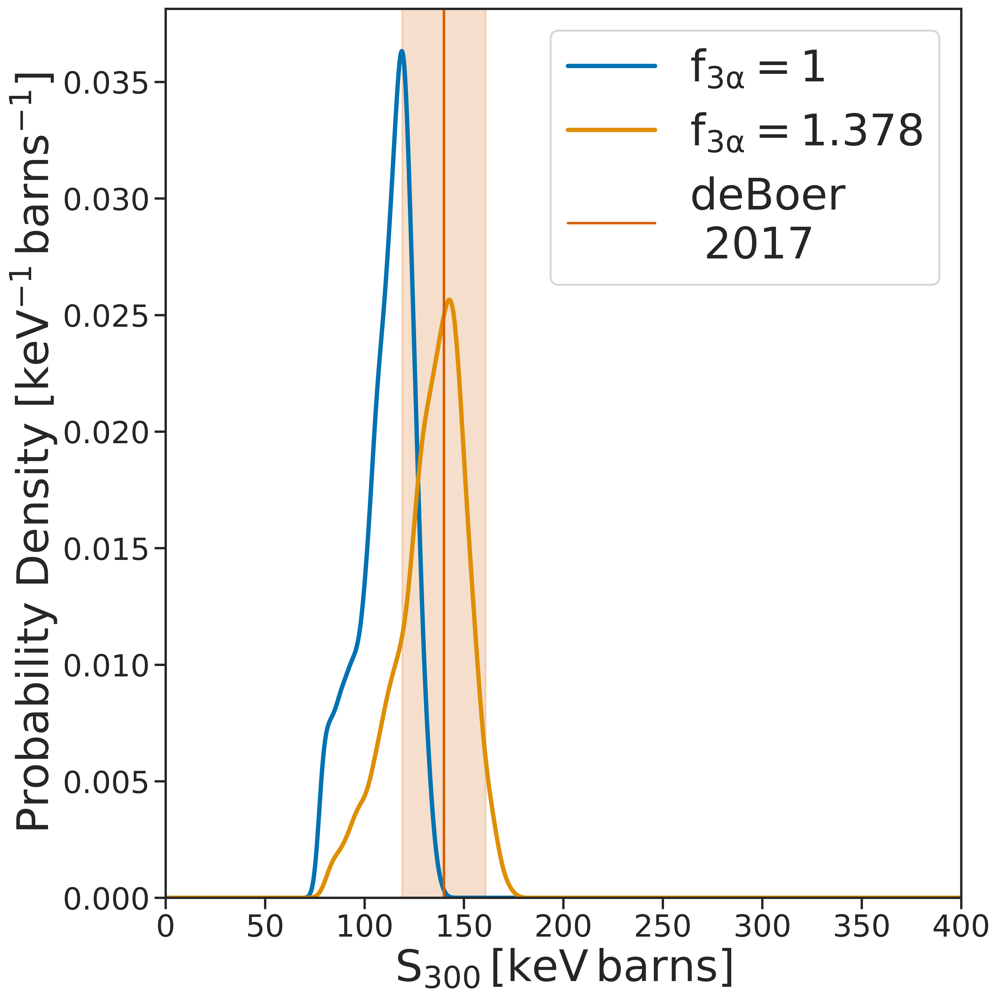

In [29]:
fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})
_=ax.plot(s_range, pdf_1, rasterized=True, lw = hist_lw, label = r"$f_{3\alpha}=1$")
_=ax.plot(s_range, pdf_2, rasterized=True, lw = hist_lw, label = r"$f_{3\alpha}=1.378$")
ax.axvline(140,label='deBoer\n 2017',color=sns.color_palette()[3], linewidth=2.0)
ax.fill_betweenx([0,max(pdf_1)*1.05],140-21,140+21,color=sns.color_palette()[3],alpha=0.2)
ax.set_xlabel(r'$S_{300}\,[\rm{keV\,barns}]$', fontsize = tfs)
ax.set_ylabel(r'Probability Density [$\rm{keV^{-1}\,barns^{-1}}$]', fontsize = tfs)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
ax.set_xlim(0,400)
ax.set_ylim(0,max(pdf_1)*1.05)
ax.legend(fontsize = tfs)
fig.tight_layout()
fig.savefig(f'{plot_dir}/S300_Farag.png')
fig.savefig(f'{plot_dir}/S300_Farag.pdf')
plt.show()

### Branching Fraction

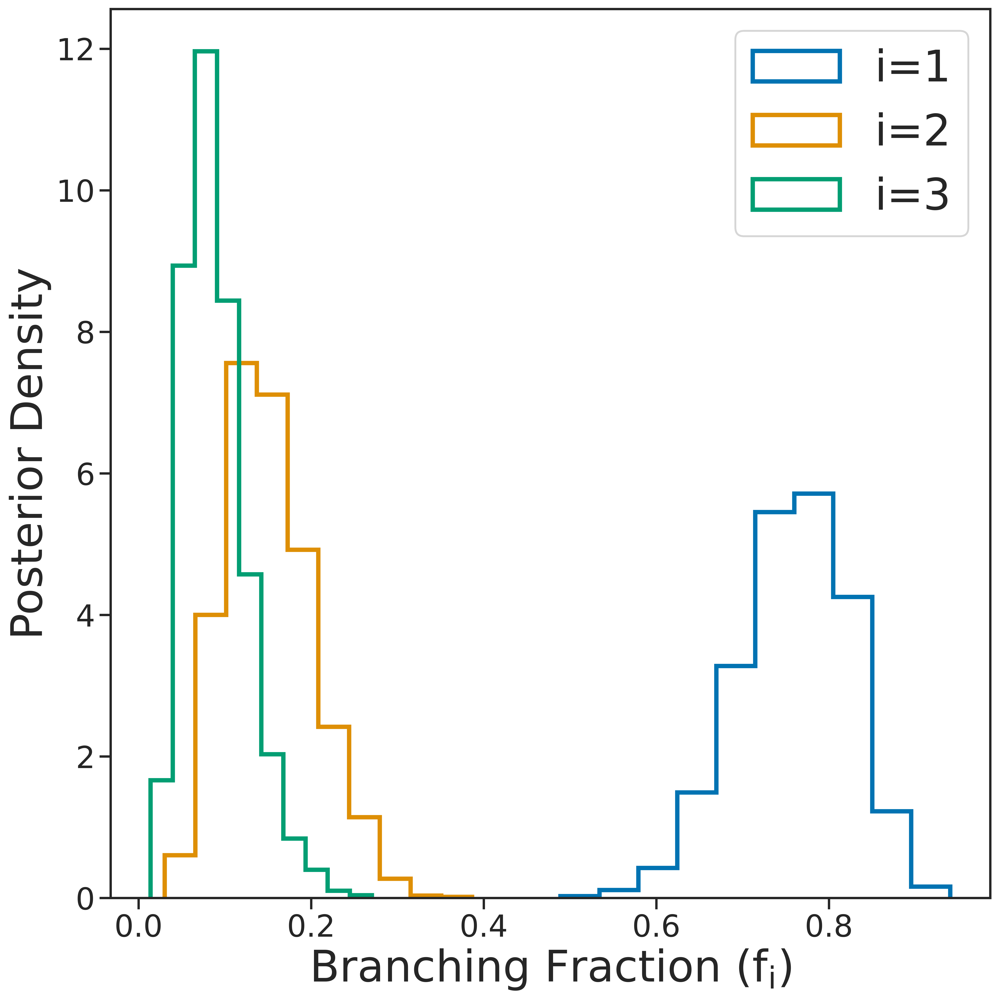

In [30]:
w_1 = posterior["w_1"].to_numpy()
w_23 = posterior["w_23"].to_numpy()
w_2 = (1.0-w_1) * w_23
w_3 = 1.0 - w_1 - w_2#(1.0 - w_1) * (1.0-w_23)
fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})
_=ax.hist(w_1, histtype = "step", density = True, label = "i=1", lw=hist_lw, rasterized = True)
_=ax.hist(w_2, histtype = "step", density = True, label = "i=2", lw=hist_lw, rasterized = True)
_=ax.hist(w_3, histtype = "step", density = True, label = "i=3", lw=hist_lw, rasterized = True)
ax.set_xlabel(r"Branching Fraction $(f_i)$", fontsize = tfs)
ax.set_ylabel("Posterior Density", fontsize = tfs)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
ax.legend(fontsize = tfs)
fig.tight_layout()
fig.savefig(f"{plot_dir}/branching_fraction.png")
fig.savefig(f"{plot_dir}/branching_fraction.pdf")
plt.show()

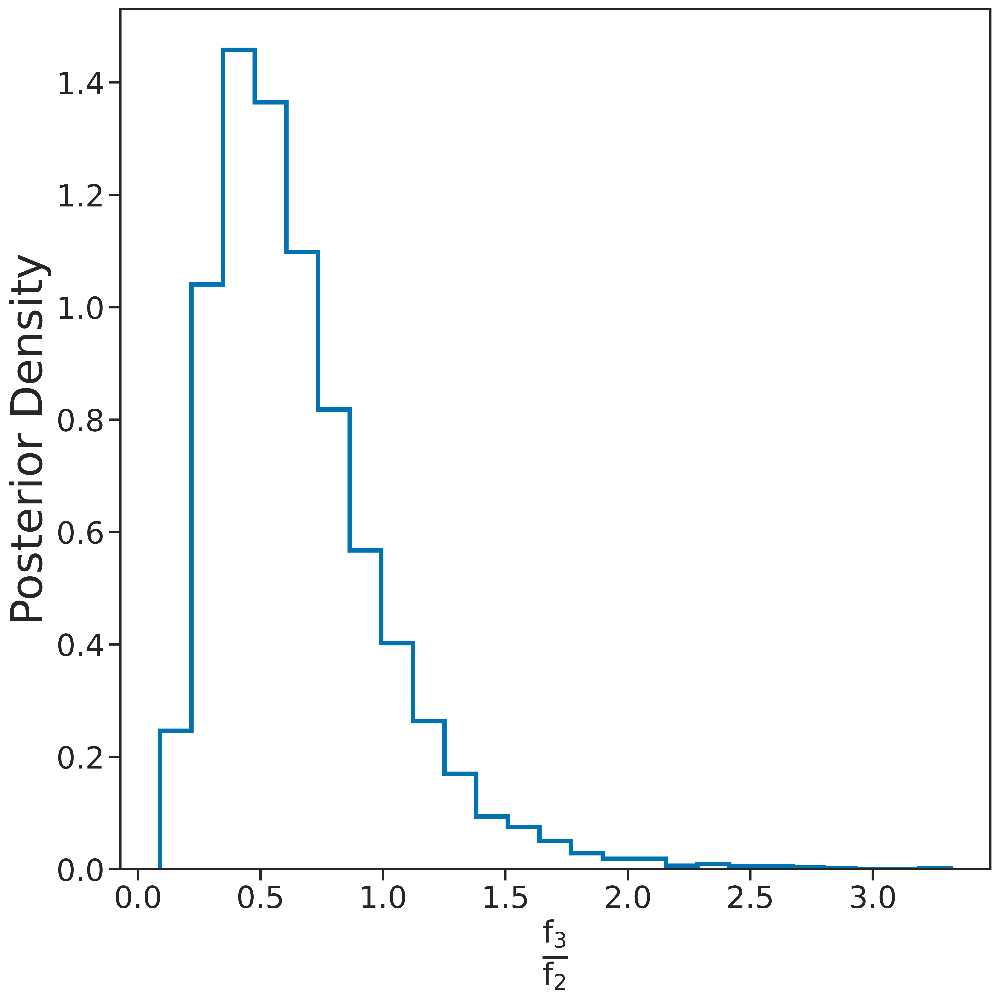

In [31]:
import numpy as np
fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})
_=ax.hist(w_3/w_2, density = True, histtype = "step", bins=25, lw=hist_lw, rasterized = True)
ax.set_xlabel(r"$\frac{f_3}{f_2}$", fontsize = tfs)
ax.set_ylabel("Posterior Density", fontsize = tfs)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
fig.tight_layout()
fig.savefig(f"{plot_dir}/hierarchical_fraction.png")
fig.savefig(f"{plot_dir}/hierarchical_fraction.pdf")
plt.show()

In [32]:
param_names = list(posterior.to_dict().keys())
Nsamp = len(w_1)

### Sub-populations

In [33]:
import numpy as np
import copy
m1_grid = np.logspace(np.log10(3.0), np.log10(300), 300)
m1_grid2 = np.logspace(np.log10(3.0), np.log10(300), 30) 
q_grid = np.linspace(0.01, 0.99, 50)
q_grid_1 = np.linspace(0.01, 1.0, 300)
m1_grids, q_grids = np.meshgrid(m1_grid, q_grid)
chieff_grid = np.linspace(-1.0,1.0, 100)
chip_grid = np.linspace(0.0,1.0, 50)
chieff_grids, m1_grids2 = np.meshgrid(chieff_grid, m1_grid)
z_grid = np.linspace(0.0001, 2.3, 1000)
dataset_1 = {"mass_1": m1_grid, "mass_ratio":q_grid_1, "chi_eff":chieff_grid, "chi_p": chip_grid, "redshift":z_grid }
dataset_2 = {"mass_1": m1_grids, "mass_ratio":q_grids, "chi_eff":chieff_grid, "chi_p": chip_grid, "redshift": z_grid }

In [34]:
# m2_grid = copy.deepcopy(m1_grid2)
# m1_grids2, m2_grids = np.meshgrid(m1_grid2, m2_grid)
dataset_3 = {"mass_1": m1_grids2, "mass_ratio":q_grid_1[:,None], "chi_eff":chieff_grids, "chi_p": chip_grid, "redshift": z_grid }


In [35]:
# chieff_grids, m1_grids2, q_grids = np.meshgrid(chieff_grid, m1_grid2, q_grid)

In [36]:
m1_grids2[:3,:3]

array([[3.        , 3.        , 3.        ],
       [3.04656338, 3.04656338, 3.04656338],
       [3.09384948, 3.09384948, 3.09384948]])

In [37]:
# param_names

In [38]:
from models_plotting import three_component_mixture_3_restricted_z
import tqdm
import copy

dists = {"m1":[],"q":[], "chieff":[], "chip":[], "z":[]}
subpops = {"1":copy.deepcopy(dists), "2":copy.deepcopy(dists), "3": copy.deepcopy(dists)}
subpops_2d = {"1":[], "2":[], "3":[]}
subpops_2d2 = {"1":[], "2":[], "3":[]}
subpops_2d3 = {"1":[], "2":[], "3":[]}
for i in tqdm.tqdm(range(Nsamp)):
    hp = {pn:posterior[pn].to_numpy()[i] for pn in param_names}
    #lamb = hp.pop("lamb")
    ll = hp.pop("log_likelihood")
    lp = hp.pop("log_prior")
    # delta_m3 = hp.pop("delta_m3")
    this_subpops = three_component_mixture_3_restricted_z(dataset_1, **hp)
    this_subpops_2d = three_component_mixture_3_restricted_z(dataset_2, **hp)
    this_subpops_2d2 = three_component_mixture_3_restricted_z(dataset_3, **hp)
    #print(this_subpops["1"].keys())
    for comp in ["1", "2", "3"]:
        for param in ["m1", "chieff", "chip", "z"]:
            subpops[comp][param].append(this_subpops[comp][param])
        
        p_m1q = this_subpops_2d[comp]["m1"] * this_subpops_2d[comp]["q"]
        subpops_2d[comp].append(p_m1q)
        # p_m1m2 = np.array(this_subpops_2d2[comp]["m1"] * this_subpops_2d2[comp]["q"]/m1_grids2)
        # p_m1m2[m1_grids2<m2_grids] = 0.0
        # subpops_2d2[comp].append(p_m1m2)
        #print(this_subpops_2d.keys())
        p_chieff_m1 = this_subpops_2d2[comp]["chieff"] * this_subpops_2d2[comp]["m1"]
        p_chieff_m1/=np.trapz(np.trapz(p_chieff_m1, chieff_grid, axis = -1),m1_grid)
        subpops_2d3[comp].append(p_chieff_m1)
        p_q = np.trapz(p_m1q, m1_grid, axis = -1)
        # if comp == "2":
        #     print(p_q)
        subpops[comp]["q"].append(p_q/np.trapz(p_q, q_grid))
    #print(subpops["2"]["q"])
    # print(subpops["1"]["chieff"][i]-subpops["2"]["chieff"][i], this_subpops["1"]["chieff"]-this_subpops["2"]["chieff"])
    # break

/home/anarya.ray/.conda/envs/gwpopulation_gpu/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
ERROR:2026-03-25 18:44:14,738:jax._src.xla_bridge:487: Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/home/anarya.ray/.conda/envs/gwpopulation_gpu/lib/python3.12/site-packages/jax/_src/xla_bridge.py", line 485, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/home/anarya.ray/.conda/envs/gwpopulation_gpu/lib/python3.12/site-packages/jax_plugins/xla_cuda12/__init__.py", line 328, in initialize
    _check_cuda_versions(raise_on_first_error=True)
  File "/home/anarya.ray/.conda/envs/gwpopulation_gpu/lib/python3.12/site-packages/jax_plugins/xla_cuda12/__init__.py", line 285, in _check_cuda_versions
    local_devic

In [39]:
ws = {"1": w_1[:,None], "2": w_2[:,None], "3": w_3[:,None]}

/tmp/ipykernel_1896/2797602921.py:8: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= (np.trapz(p_chieff, chieff_grid, axis = -1)[:,None])


<Figure size 640x480 with 0 Axes>

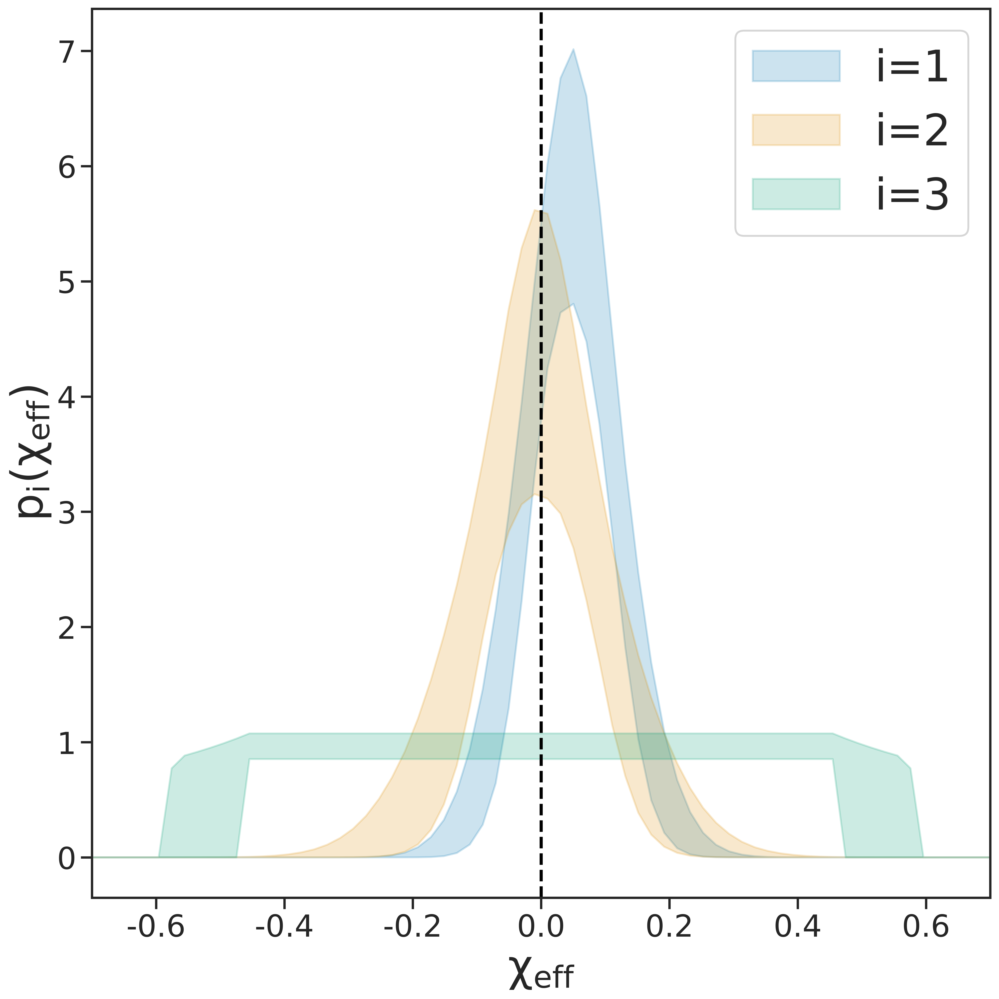

In [40]:
%matplotlib inline
plt.clf()
fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})
for i,comp in enumerate(["1", "2", "3"]):
    p_chieff = np.array(subpops[comp]["chieff"])
    p_chieff/= (np.trapz(p_chieff, chieff_grid, axis = -1)[:,None])
    ax.fill_between(chieff_grid, np.quantile(p_chieff, 0.05, axis = 0), np.quantile(p_chieff, 0.95, axis = 0), alpha = 0.2, color = colors[i],
                    label = f"i={i+1}", rasterized = True)
    #break
ax.axvline(0.0, color = "black", ls = "dashed", lw = 2.5)
ax.set_xlabel(r"$\chi_{eff}$", fontsize = tfs)
ax.set_ylabel(r"$p_i(\chi_{eff})$", fontsize = tfs)
ax.set_xlim(-0.7,0.7)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
ax.legend(fontsize = tfs)
fig.tight_layout()
fig.savefig(f"{plot_dir}/chieff.png")
fig.savefig(f"{plot_dir}/chieff.pdf")

/tmp/ipykernel_1896/1727477197.py:20: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff = np.trapz(p_chieff_2d, m1_grid, axis=1) * ws[comp]
/tmp/ipykernel_1896/1727477197.py:22: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff+=np.trapz(p_chieff_2d, m1_grid, axis=1) * ws[comp]
/tmp/ipykernel_1896/1727477197.py:24: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= (np.trapz(p_chieff, chieff_grid, axis = -1)[:,None])


<Figure size 640x480 with 0 Axes>

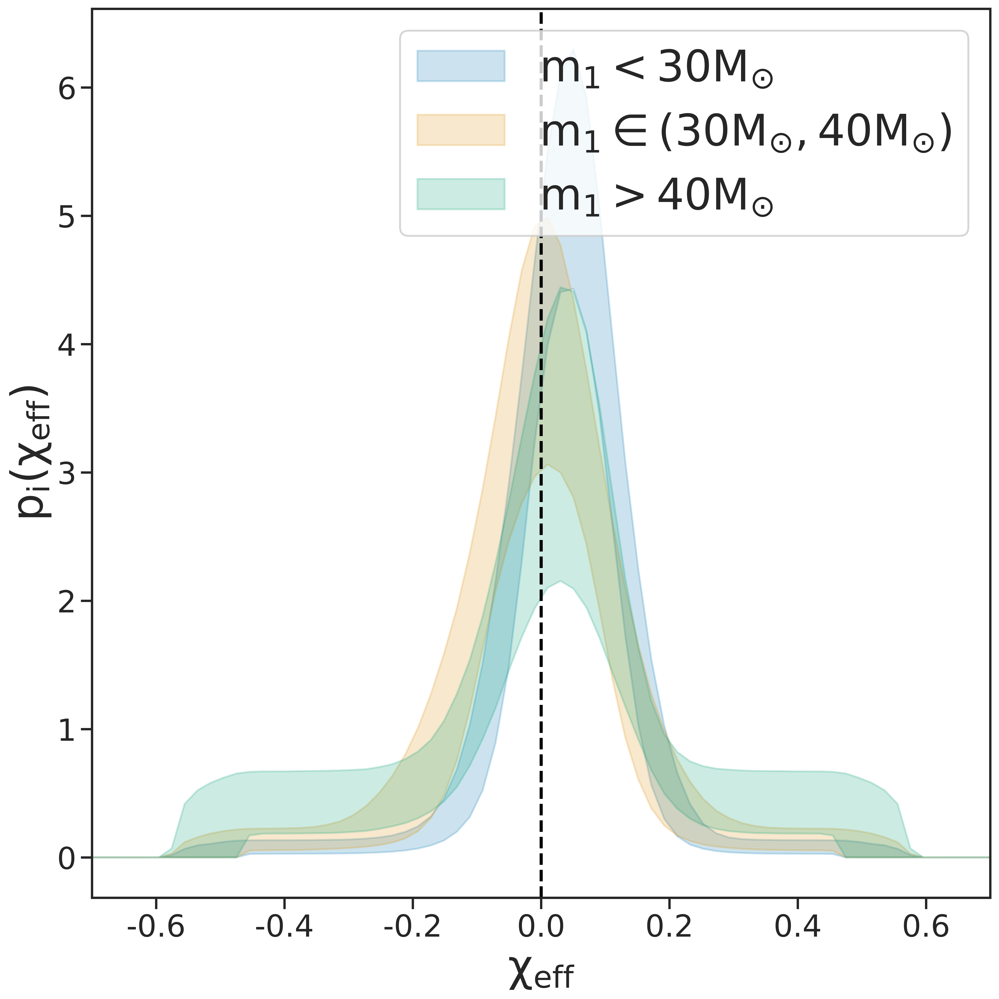

In [41]:
%matplotlib inline
plt.clf()
fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})
labels = [r"$m_1<30M_{\odot}$", r'$m_1 \in(30M_{\odot},40M_{\odot})$', r'$m_1 >40M_{\odot}$']
p_chieff_given_m1 = []
for reg in range(3):
    if reg==0:
        arg = m1_grids2<=30
    elif reg==1:
        arg = (m1_grids2>=30) * (m1_grids2<=40)
    else:
        arg = m1_grids2>=40
        
    for i,comp in enumerate(["1", "2", "3"]):
        p_chieff_2d = copy.deepcopy(np.array(subpops_2d3[comp]))
        p_chieff_2d[:,~arg] = 0.0
        if i==0:
            p_chieff = np.trapz(p_chieff_2d, m1_grid, axis=1) * ws[comp]
        else:
            p_chieff+=np.trapz(p_chieff_2d, m1_grid, axis=1) * ws[comp]
                                    
    p_chieff/= (np.trapz(p_chieff, chieff_grid, axis = -1)[:,None])
    p_chieff_given_m1.append(p_chieff)
    ax.fill_between(chieff_grid, np.quantile(p_chieff, 0.05, axis = 0), np.quantile(p_chieff, 0.95, axis = 0), alpha = 0.2, color = colors[reg],
                    label = labels[reg], rasterized = True)
    #break
ax.axvline(0.0, color = "black", ls = "dashed", lw = 2.5)
ax.set_xlabel(r"$\chi_{eff}$", fontsize = tfs)
ax.set_ylabel(r"$p_i(\chi_{eff})$", fontsize = tfs)
ax.set_xlim(-0.7,0.7)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
ax.legend(fontsize = tfs)
fig.tight_layout()
fig.savefig(f"{plot_dir}/chieff_m1.png")
fig.savefig(f"{plot_dir}/chieff_m1.pdf")

In [46]:
import glob
SMT_files = glob.glob("Brielle_2025/*.h5")
SMT_files

['Brielle_2025/bbh_params_CO_contatct_Shukbold_all.h5',
 'Brielle_2025/bbh_params_CO_contatct_Fryer_all.h5',
 'Brielle_2025/bbh_params_CO_contatct_PattonShukbold_all.h5']

In [47]:
labels = ["Sukhbold+16\n-Engine+W20","Fryer+12\n-Delayed)", "Patton&\nSukhbold+20"]

In [48]:
bws = [0.45, 0.5, 0.35]

[-0.3   -0.225 -0.15  -0.075  0.     0.075  0.15   0.225  0.3    0.375
  0.45   0.525  0.6  ]
1000000


/tmp/ipykernel_1896/2501024861.py:15: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= (np.trapz(p_chieff, chieff_grid, axis = -1)[:,None])
/tmp/ipykernel_1896/2501024861.py:28: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pdf /= np.trapz(pdf, chieff_grid)


3.3769 Sukhbold+16
-Engine+W20
1000000
4.1189 Fryer+12
-Delayed)
1000000
2.6481 Patton&
Sukhbold+20


<Figure size 640x480 with 0 Axes>

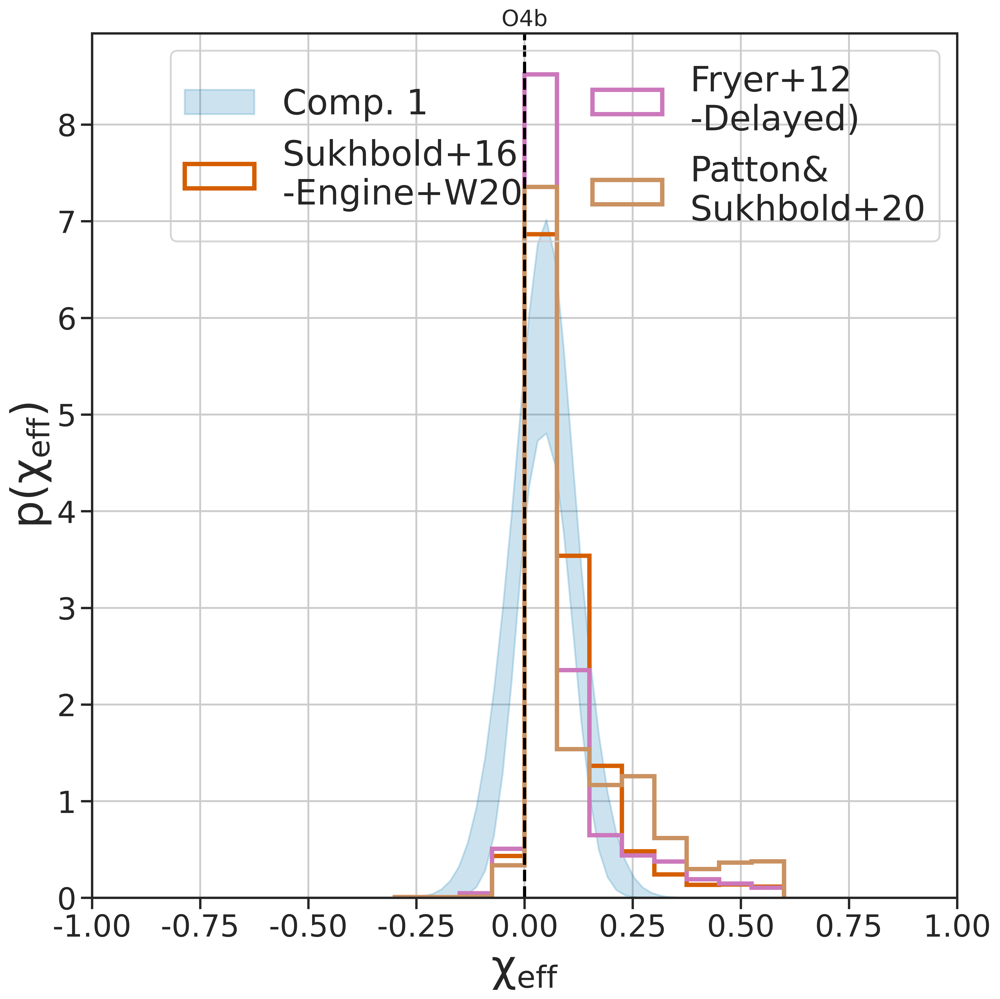

In [50]:
%matplotlib inline
plt.clf()
fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})
nb13 = 5
bins  = np.append(np.append(np.linspace(-0.3,0,nb13)[:-1], np.linspace(0.,0.3,nb13) ), np.linspace(0.3,0.6,nb13)[1:])
# bins = np.linspace(-0.3,0.7, 10)
# bins = np.linspace(-1,1, 20)
print(bins)
for i,comp in enumerate(["1", "2", "3"]):
    if i>=1:
        continue
    p_chieff = np.array(subpops[comp]["chieff"])
    p_chieff/= (np.trapz(p_chieff, chieff_grid, axis = -1)[:,None])
    ax.fill_between(chieff_grid, np.quantile(p_chieff, 0.05, axis = 0), np.quantile(p_chieff, 0.95, axis = 0), alpha = 0.2, color = colors[i],
                    label = f"Comp. {i+1}", rasterized = True)
    #break
for i, SMT_file in enumerate(SMT_files):
    with h5py.File(SMT_file, "r") as hf:
        chieffs = hf["parameters"][()][:,-2]
        m1s = hf["parameters"][()][:,0]
    # chieffs = chieffs[m1s<15]
    print(len(chieffs))
    # bins = np.linspace(-0.3,0,10)
    kde = gaussian_kde(chieffs, bw_method = bws[i])
    pdf = kde(chieff_grid)
    pdf /= np.trapz(pdf, chieff_grid)
    # ax.plot(chieff_grid, pdf, lw = hist_lw, color = colors[i+3], label = labels[i])
    print(100.*sum(chieffs<0)/len(chieffs), labels[i])
    ax.hist(chieffs, density = True, histtype = "step", lw = hist_lw, bins = bins, color = colors[i+3], label = labels[i])
ax.axvline(0.0, color = "black", ls = "dashed", lw = 2.5)
ax.set_xlabel(r"$\chi_{eff}$", fontsize = tfs)
ax.set_ylabel(r"$p(\chi_{eff})$", fontsize = tfs)
ax.set_xlim(-1.0,1.0)
ax.grid()
# ax.set_ylim(0,1.2)
ax.set_title("O4b")
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
legend = ax.legend(fontsize = tfs*0.8, ncol = 2)
legend.get_frame().set_facecolor('none') 
fig.tight_layout()
fig.savefig(f"{plot_dir}/chieff_1_hist.png")
fig.savefig(f"{plot_dir}/chieff_1_hist.pdf")

In [43]:
import yaml
with open('/home/anarya.ray/gppop-prod/prod-test/o4b/gppop-o4-code-review/m1m2chi/gwtc-5.yaml', "r") as stream:
    config = yaml.full_load(stream)

In [44]:
event_list = list(config["pe_summary_event_dict"].keys())
waveform_list = np.array(list(config["pe_summary_event_dict"].values()))[:,0].tolist()

In [45]:
popsummary = popresult.PopulationResult(fname = '/home/anarya.ray/public_html/parametric_o4b/pchieff_given_m1_popsummary.hdf5', 
                                        events = event_list, event_waveforms = waveform_list, event_sample_IDs = np.arange(len(event_list)),
                                        event_parameters = ['m1','m2','chi_eff'],model_names = [f'parametric_m1qchieffchipz'])

In [47]:
popsummary.set_rates_on_grids('effective_inspiral_spin_norm',[ 'chi', 'm1'], chieff_grid.reshape((len(chieff_grid),1)), np.array(p_chieff_given_m1), group="posterior",overwrite=True)

In [47]:
pm1m2_marg = sum(np.array(subpops_2d2[comp]) for comp in subpops_2d2.keys())
pm1m2_marg.shape

(4970, 30, 30)

In [69]:
m_weights1 = {"1": [], "2":[], "3":[]}
m_weights2 = {"1": [], "2":[], "3":[]}
arg1 = ((m1_grids2 <= 40) * (m1_grids2>=30) + 
        (m2_grids <= 40) * (m2_grids>=30))
arg2 = ~arg1

for i, this_pm1m2_marg in enumerate(tqdm.tqdm(pm1m2_marg)):
    weights_denom = np.trapz(np.trapz(this_pm1m2_marg * arg1, m1_grid2, axis = -1), m2_grid)
    for _, comp in enumerate(["1", "2", "3"]):
        #print(comp in subpops_2d2.keys())
        p_m1m2 = subpops_2d2[comp][i]
        # p_m1m2/= (np.trapz(np.trapz(p_m1m2, m1_grid, axis=-1), m2_grid))
        m_weights1[comp].append(np.trapz(np.trapz(p_m1m2 * arg1, m1_grid2, 
                                                  axis=-1), m2_grid)/weights_denom)
for i, this_pm1m2_marg in enumerate(tqdm.tqdm(pm1m2_marg)):
    weights_denom = np.trapz(np.trapz(this_pm1m2_marg * arg2, m1_grid2, axis = -1),
                             m2_grid)
    for _, comp in enumerate(["1", "2", "3"]):
        #print(comp in subpops_2d2.keys())
        p_m1m2 = subpops_2d2[comp][i]
        # p_m1m2/= (np.trapz(np.trapz(p_m1m2, m1_grid, axis=-1), m2_grid))
        m_weights2[comp].append(np.trapz(np.trapz(p_m1m2 * arg2, m1_grid2, 
                                                  axis=-1), m2_grid)/weights_denom)

  0%|          | 0/4970 [00:00<?, ?it/s]/tmp/ipykernel_2582/1970625380.py:8: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  weights_denom = np.trapz(np.trapz(this_pm1m2_marg * arg1, m1_grid2, axis = -1), m2_grid)
/tmp/ipykernel_2582/1970625380.py:13: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  m_weights1[comp].append(np.trapz(np.trapz(p_m1m2 * arg1, m1_grid2,
  0%|          | 0/4970 [00:00<?, ?it/s]/tmp/ipykernel_2582/1970625380.py:16: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  weights_denom = np.trapz(np.trapz(this_pm1m2_marg * arg2, m1_grid2, axis = -1),
/tmp/ipykernel_2582/1970625380.py:22: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `s

In [71]:
m_weights1 = {key:np.array(weight) for key, weight in m_weights1.items()}
m_weights2 = {key:np.array(weight) for key, weight in m_weights2.items()}

In [72]:
m_weights1_norm = {key: weight/sum(val for val in m_weights1.values()) for key, 
                weight in m_weights1.items()}
m_weights2_norm = {key: weight/sum(val for val in m_weights1.values()) for key, 
                weight in m_weights2.items()}

In [62]:
m_weights1_norm["1"].shape

(4970,)

/tmp/ipykernel_2582/2147192214.py:8: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= (np.trapz(p_chieff, chieff_grid, axis = -1)[:,None])
/tmp/ipykernel_2582/2147192214.py:11: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pdf/= (np.trapz(pdf, chieff_grid)[:,None])
100%|██████████| 4970/4970 [00:00<00:00, 27917.87it/s]
/tmp/ipykernel_2582/2147192214.py:26: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= (np.trapz(p_chieff, chieff_grid, axis = -1)[:,None])
/tmp/ipykernel_2582/2147192214.py:29: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pdf/= (np.trapz(pdf, chieff_grid)[:,None])
100%|██████████| 4970/4970 [

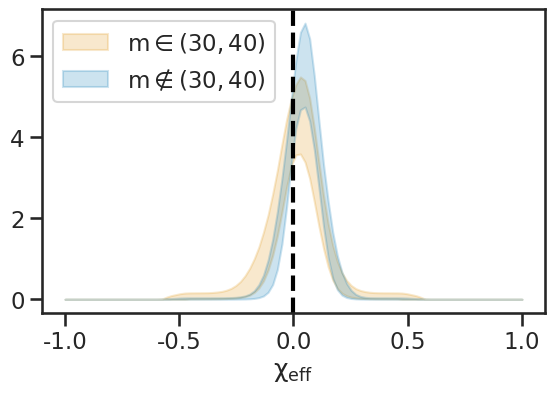

In [77]:
reg = "III"
%matplotlib inline
plt.clf()
pdf = np.zeros((Nsamp, len(chieff_grid)))
for i,comp in enumerate(["1", "2", "3"]):
    
    p_chieff = np.array(subpops[comp]["chieff"])
    p_chieff/= (np.trapz(p_chieff, chieff_grid, axis = -1)[:,None])
    pdf+= p_chieff * (m_weights1_norm[comp][:,None])

pdf/= (np.trapz(pdf, chieff_grid)[:,None])
cdf = cumtrapz(pdf, chieff_grid, axis = -1, initial = 0.0)
cdf/=(cdf[:,-1][:,None])
frac = []
for this_cdf in tqdm.tqdm(cdf):
    inpcdf = interp1d(chieff_grid, this_cdf)
    frac.append(inpcdf(0.0))
frac_1 = np.array(frac)
plt.fill_between(chieff_grid, np.quantile(pdf, 0.05, axis = 0), np.quantile(pdf, 0.95, axis = 0),
                 alpha = 0.2, color = colors[1], label = r"$m \in (30,40)$"
         )
pdf = np.zeros((Nsamp, len(chieff_grid)))
for i,comp in enumerate(["1", "2", "3"]):
    
    p_chieff = np.array(subpops[comp]["chieff"])
    p_chieff/= (np.trapz(p_chieff, chieff_grid, axis = -1)[:,None])
    pdf+= p_chieff * (m_weights2_norm[comp][:,None])

pdf/= (np.trapz(pdf, chieff_grid)[:,None])
cdf = cumtrapz(pdf, chieff_grid, axis = -1, initial = 0.0)
cdf/=(cdf[:,-1][:,None])
frac = []
for this_cdf in tqdm.tqdm(cdf):
    inpcdf = interp1d(chieff_grid, this_cdf)
    frac.append(inpcdf(0.0))
frac_2 = np.array(frac)
plt.fill_between(chieff_grid, np.quantile(pdf, 0.05, axis = 0), np.quantile(pdf, 0.95, axis = 0),
                 alpha = 0.2, color = colors[0], label = r"$m \notin (30,40)$"
         )
# plt.plot(q, np.quantile(p_qs2, 0.05, axis = 0), ls = "dashed", lw = 2.0, color = colors[2], 
#          label = "Ray and Kalogera 2025")
# plt.plot(q, np.quantile(p_qs2, 0.95, axis = 0), ls = "dashed", lw = 2.0, color = colors[2])
# plt.semilogy()
# plt.ylim(1e-3, 10)
# plt.ylim(0.4, 3.0)
    #break
# plt.xlim(0.1,1.0)
plt.axvline(0.0, ls = "dashed", lw = 3.0, color = "black")
plt.xlabel(r"$\chi_{eff}$")
plt.legend()
plt.tight_layout()
plt.savefig(f"{plot_dir}/chi_eff_3040.png")
plt.show()

In [41]:
from scipy.ndimage import gaussian_filter
def find_levels(density, level, smooth = False):
    Z_smooth = gaussian_filter(density, sigma=2) if smooth else copy.deepcopy(density)

    # --- Compute contour levels for 90% and 50% probability ---
    Z_flat = Z_smooth.flatten()
    idx = np.argsort(Z_flat)[::-1]
    Z_sorted = Z_flat[idx]
    cdf = np.cumsum(Z_sorted)
    cdf /= cdf[-1]
    return Z_sorted[np.searchsorted(cdf, level)], Z_smooth

/tmp/ipykernel_158/3576237169.py:10: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= np.trapz(np.trapz(p_chieff, chieff_grid, axis=-1), chip_grid)
/tmp/ipykernel_158/3576237169.py:33: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize = tfs)


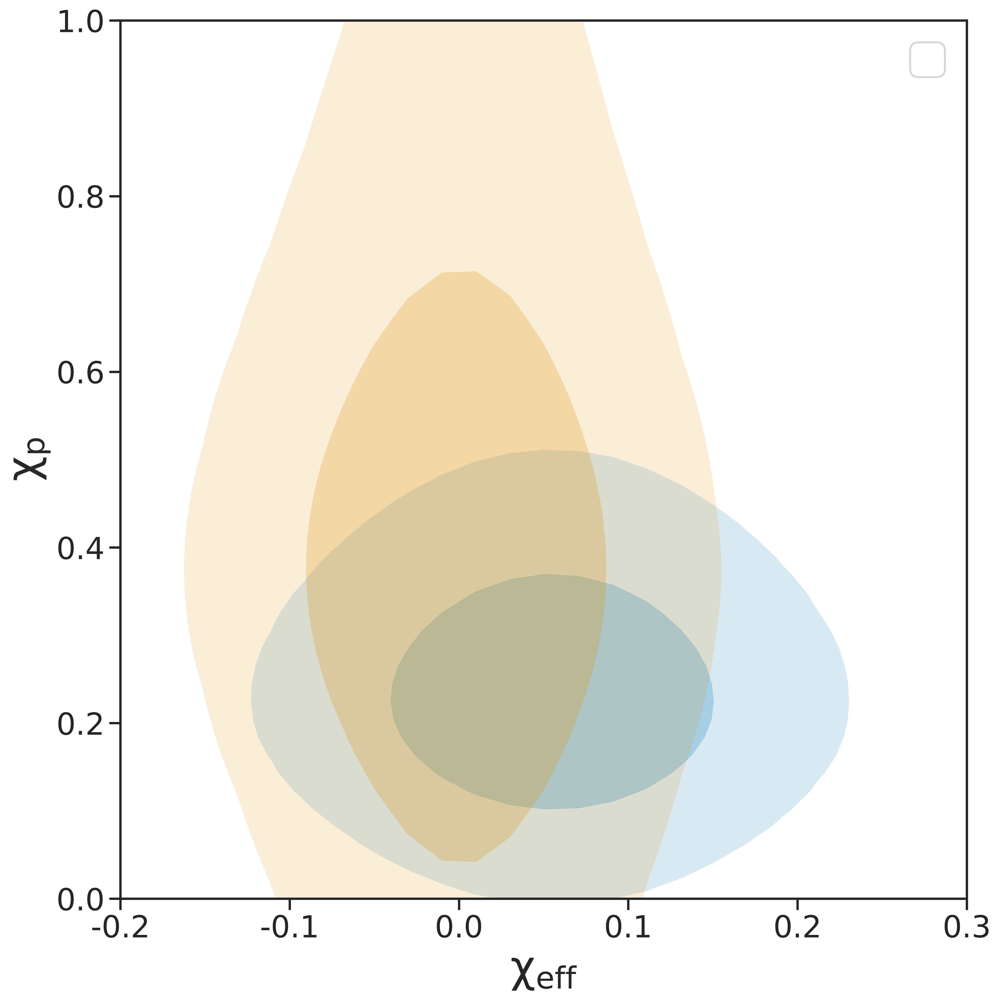

In [70]:
#subpops_2d3
%matplotlib inline
fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import ListedColormap
for i,comp in enumerate(["1", "2", "3"][:-1]):
    p_chieff = np.mean(np.array(subpops_2d3[comp]), axis=0)
    p_chieff/= np.trapz(np.trapz(p_chieff, chieff_grid, axis=-1), chip_grid)
    levels = []
    for level in [ 0.5, 0.9]:
        contour, Z_smooth = find_levels(p_chieff, level)
        levels.append(contour)
    levels.append(Z_smooth.max())
    levels = sorted(levels)
    base = colors[i]
    cmap = ListedColormap([
        (*base, 0.15),  # 90% region (lighter)
        (*base, 0.35),  # 50% region (darker)
    ])

    
    
    # p_chieff/= (np.trapz(p_chieff, chieff_grid, axis = -1)[:,None])
    ax.contourf(chieff_grids, chip_grids, Z_smooth, levels = levels, cmap = cmap)#fill_between(chieff_grid, np.quantile(p_chieff, 0.05, axis = 0), np.quantile(p_chieff, 0.95, axis = 0), alpha = 0.2, color = colors[i],
                    # label = f"i={i+1}", rasterized = True)
ax.set_xlabel(r"$\chi_{eff}$", fontsize = tfs)
ax.set_ylabel(r"$\chi_{p}$", fontsize = tfs)
ax.set_xlim(-0.2,0.3)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
ax.legend(fontsize = tfs)
fig.tight_layout()
fig.savefig(f"{plot_dir}/chip_chieff_mean.png")
fig.savefig(f"{plot_dir}/chip_chieff_mean.pdf")
plt.show()

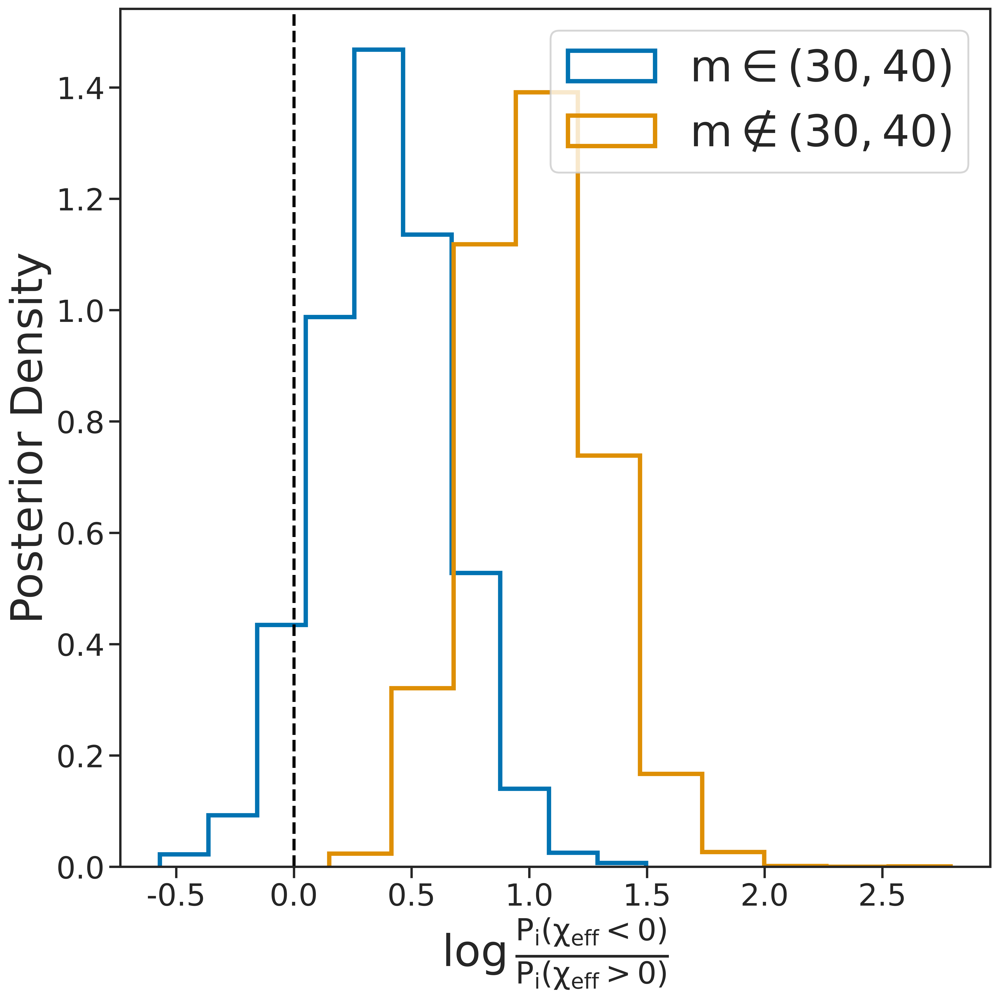

In [82]:
fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})

_ = ax.hist(-np.log(frac_1/(1-frac_1)), histtype = "step", label = r"$m \in (30,40)$", density = True, lw=hist_lw, rasterized = True)
_ = ax.hist(-np.log(frac_2/(1-frac_2)), histtype = "step", label = r"$m \notin (30,40)$", density = True, lw=hist_lw, rasterized = True)
ax.set_xlabel(r"$\log \frac{P_i(\chi_{eff}<0)}{P_i(\chi_{eff}>0)}$", fontsize = tfs)
ax.set_ylabel("Posterior Density", fontsize = tfs)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
ax.axvline(0., color = "black", ls ="dashed", lw = 2.5)
ax.legend(fontsize = tfs)
fig.tight_layout()
fig.savefig(f"{plot_dir}/chieff_frac_3040.png")
fig.savefig(f"{plot_dir}/chieff_frac_3040.pdf")

In [1]:
subpops_2d2.keys()

NameError: name 'subpops_2d2' is not defined

In [ ]:
%matplotlib inline
plt.clf()
fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})
for i,comp in enumerate(["1", "2", "3"]):
    p_chieff = np.array(subpops[comp]["chieff"])
    p_chieff/= (np.trapz(p_chieff, chieff_grid, axis = -1)[:,None])
    ax.fill_between(chieff_grid, np.quantile(p_chieff, 0.05, axis = 0), np.quantile(p_chieff, 0.95, axis = 0), alpha = 0.2, color = colors[i],
                    label = f"i={i+1}", rasterized = True)
    #break
ax.axvline(0.0, color = "black", ls = "dashed", lw = 2.5)
ax.set_xlabel(r"$\chi_{eff}$", fontsize = tfs)
ax.set_ylabel(r"$p_i(\chi_{eff})$", fontsize = tfs)
ax.set_xlim(-0.7,0.7)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
ax.legend(fontsize = tfs)
fig.tight_layout()
fig.savefig(f"{plot_dir}/chieff.png")
fig.savefig(f"{plot_dir}/chieff.pdf")

/tmp/ipykernel_1697/1402536730.py:4: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= (np.trapz(p_chieff, chieff_grid, axis = -1)[:,None])
100%|██████████| 4970/4970 [00:00<00:00, 28389.84it/s]
/tmp/ipykernel_1697/1402536730.py:16: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= (np.trapz(p_chieff, chieff_grid, axis = -1)[:,None])
100%|██████████| 4970/4970 [00:00<00:00, 28146.27it/s]


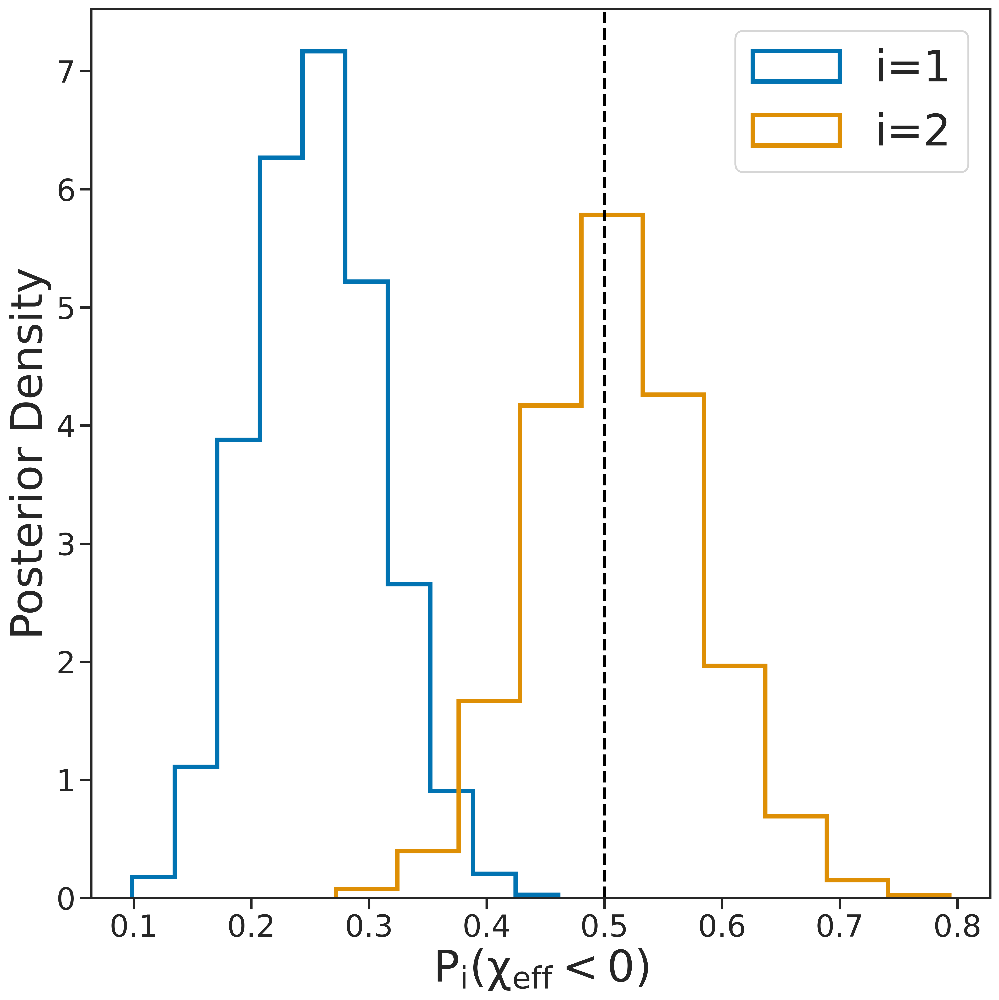

In [40]:
from scipy.integrate import cumulative_trapezoid as cumtrapz
from scipy.interpolate import interp1d
p_chieff = subpops["1"]["chieff"]
p_chieff/= (np.trapz(p_chieff, chieff_grid, axis = -1)[:,None])
cdf = cumtrapz(p_chieff, chieff_grid, axis = -1, initial = 0.0)
cdf/=(cdf[:,-1][:,None])
frac = []
for this_cdf in tqdm.tqdm(cdf):
    inpcdf = interp1d(chieff_grid, this_cdf)
    frac.append(inpcdf(0.0))
frac_1 = np.array(frac)

from scipy.integrate import cumulative_trapezoid as cumtrapz
from scipy.interpolate import interp1d
p_chieff = subpops["2"]["chieff"]
p_chieff/= (np.trapz(p_chieff, chieff_grid, axis = -1)[:,None])
cdf = cumtrapz(p_chieff, chieff_grid, axis = -1, initial = 0.0)
cdf/=(cdf[:,-1][:,None])
frac = []
for this_cdf in tqdm.tqdm(cdf):
    inpcdf = interp1d(chieff_grid, this_cdf)
    frac.append(inpcdf(0.0))
frac_2 = np.array(frac)

fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})

_ = ax.hist(frac_1, histtype = "step", label = "i=1", density = True, lw=hist_lw, rasterized = True)
_ = ax.hist(frac_2, histtype = "step", label = "i=2", density = True, lw=hist_lw, rasterized = True)
ax.set_xlabel(r"$P_i(\chi_{eff}<0)$", fontsize = tfs)
ax.set_ylabel("Posterior Density", fontsize = tfs)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
ax.axvline(0.5, color = "black", ls ="dashed", lw = 2.5)
ax.legend(fontsize = tfs)
fig.tight_layout()
fig.savefig(f"{plot_dir}/chieff_frac.png")
fig.savefig(f"{plot_dir}/chieff_frac.pdf")

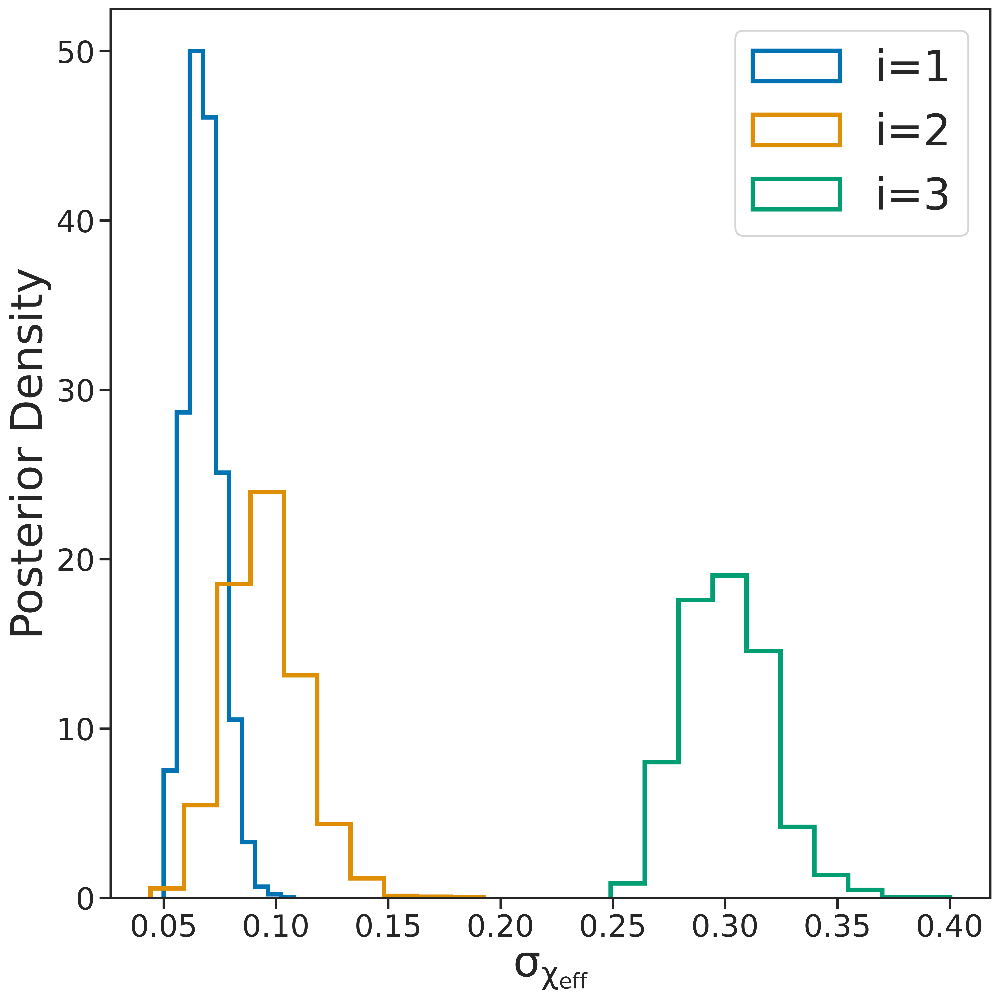

In [126]:
fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})

_ = ax.hist(posterior["sigma_chi_eff1"].to_numpy(), histtype = "step", label = "i=1", density = True, lw=hist_lw, rasterized = True)
_ = ax.hist(posterior["sigma_chi_eff2"].to_numpy(), histtype = "step", label = "i=2", density = True, lw=hist_lw, rasterized = True)
_ = ax.hist(posterior["w_chi_eff3"].to_numpy()/np.sqrt(3), histtype = "step", label = "i=3", density = True, lw=hist_lw, rasterized = True)
ax.set_xlabel(r"$\sigma_{\chi_{eff}}$", fontsize = tfs)
ax.set_ylabel("Posterior Density", fontsize = tfs)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
#ax.axvline(0.5, color = "black", ls ="dashed", lw = 2.5)
ax.legend(fontsize = tfs)
fig.tight_layout()
fig.savefig(f"{plot_dir}/chieff_width.png")
fig.savefig(f"{plot_dir}/chieff_width.pdf")

In [26]:
credible_interval(posterior["sigma_chi_eff2"], kind = "hpd"), credible_interval(posterior["sigma_chi_p2"], kind = "hpd")

({'central': np.float64(0.07645899980010898),
  'low': np.float64(0.043915031749348535),
  'high': np.float64(0.10817172874925923),
  'plus': np.float64(0.031712728949150254),
  'minus': np.float64(0.032543968050760444)},
 {'central': np.float64(0.22915875825195078),
  'low': np.float64(0.08558261377061457),
  'high': np.float64(1.2511409533247062),
  'plus': np.float64(1.0219821950727555),
  'minus': np.float64(0.1435761444813362)})

/tmp/ipykernel_157/2167793464.py:8: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= (np.trapz(p_chieff, chip_grid, axis = -1)[:,None])


<Figure size 640x480 with 0 Axes>

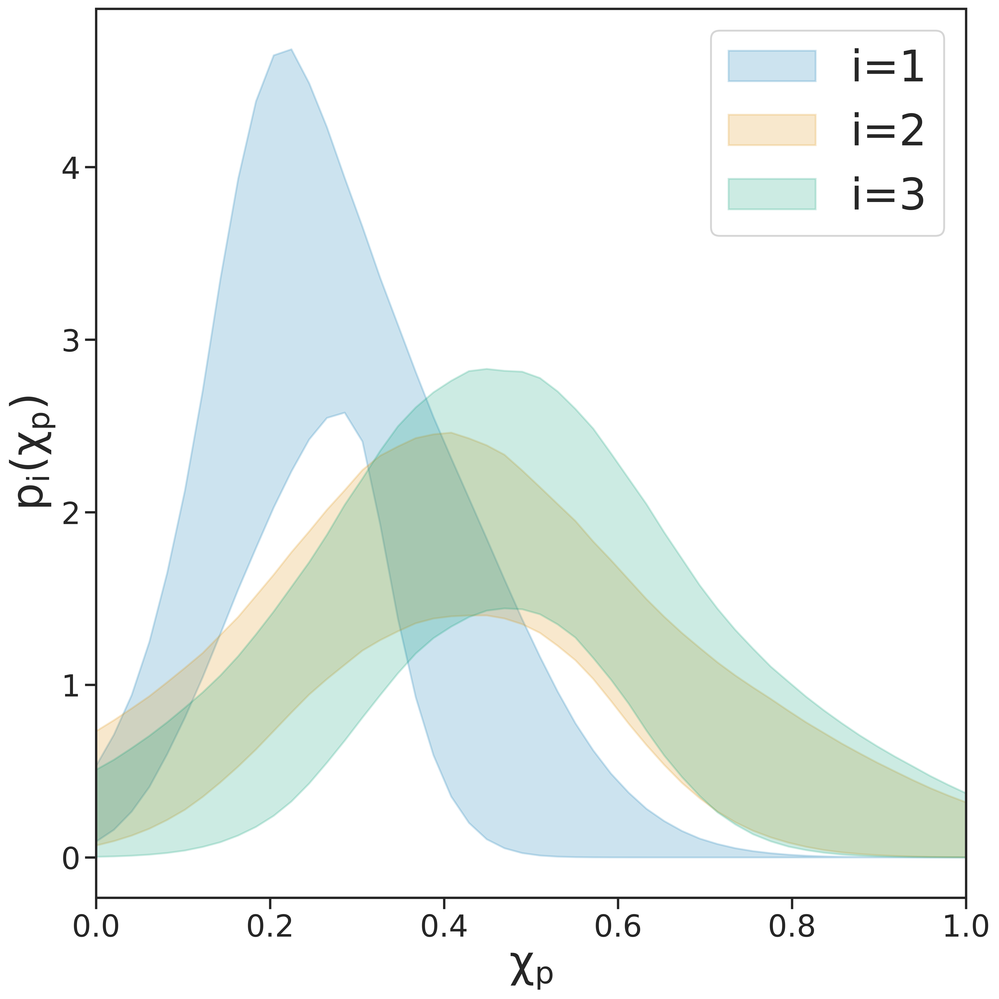

In [127]:
%matplotlib inline
plt.clf()
fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})
for i,comp in enumerate(["1", "2", "3"]):
    p_chieff = np.array(subpops[comp]["chip"])
    p_chieff/= (np.trapz(p_chieff, chip_grid, axis = -1)[:,None])
    ax.fill_between(chip_grid, np.quantile(p_chieff, 0.05, axis = 0), np.quantile(p_chieff, 0.95, axis = 0), alpha = 0.2, color = colors[i],
                    label = f"i={i+1}", rasterized = True)
    #break
#ax.axvline(0.0, color = "black", ls = "dashed", lw = 2.5)
ax.set_xlabel(r"$\chi_{p}$", fontsize = tfs)
ax.set_ylabel(r"$p_i(\chi_{p})$", fontsize = tfs)
ax.set_xlim(0,1.0)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
ax.legend(fontsize = tfs)
fig.tight_layout()
fig.savefig(f"{plot_dir}/chip.png")
fig.savefig(f"{plot_dir}/chip.pdf")

/tmp/ipykernel_157/3021345284.py:4: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= (np.trapz(p_chieff, chip_grid, axis = -1)[:,None])
100%|██████████| 4970/4970 [00:00<00:00, 27067.83it/s]
/tmp/ipykernel_157/3021345284.py:16: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= (np.trapz(p_chieff, chip_grid, axis = -1)[:,None])
100%|██████████| 4970/4970 [00:00<00:00, 27161.22it/s]
/tmp/ipykernel_157/3021345284.py:26: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= (np.trapz(p_chieff, chip_grid, axis = -1)[:,None])
100%|██████████| 4970/4970 [00:00<00:00, 27393.11it/s]


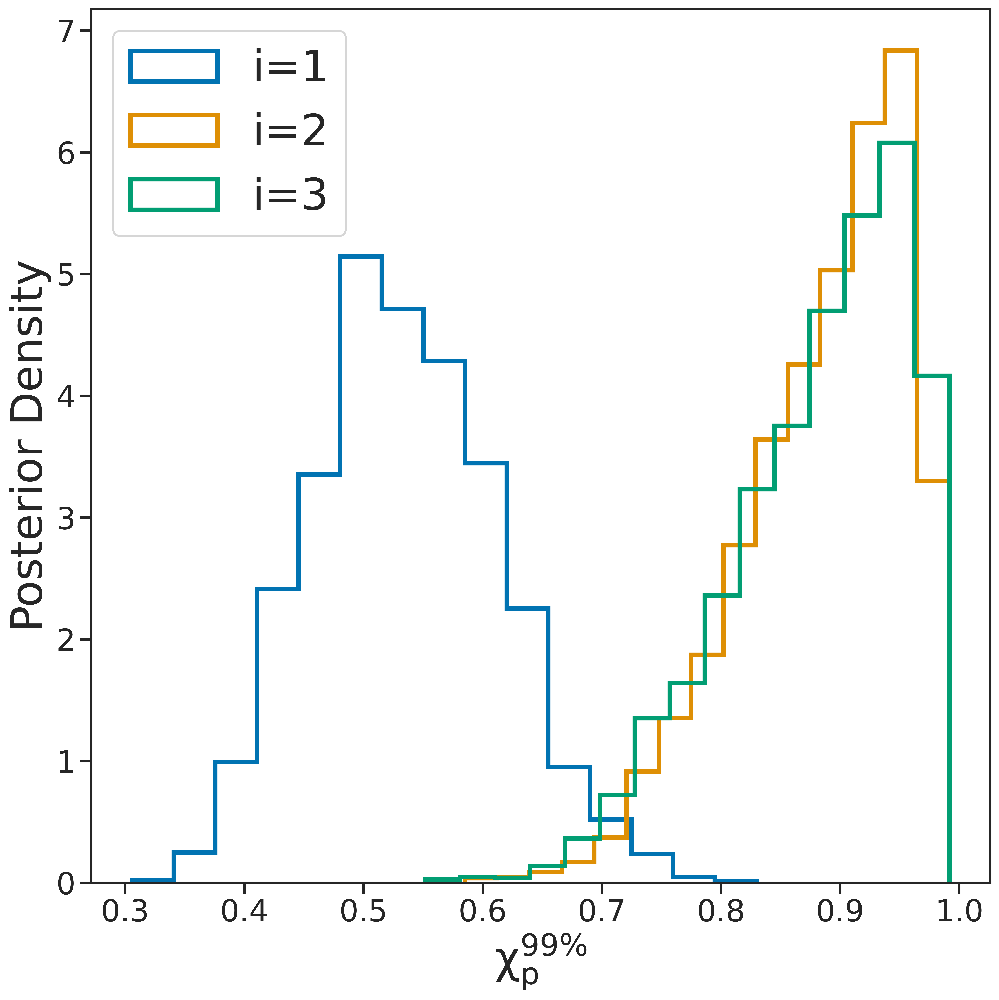

In [128]:
from scipy.integrate import cumulative_trapezoid as cumtrapz
from scipy.interpolate import interp1d
p_chieff = subpops["1"]["chip"]
p_chieff/= (np.trapz(p_chieff, chip_grid, axis = -1)[:,None])
cdf = cumtrapz(p_chieff, chip_grid, axis = -1, initial = 0.0)
cdf/=(cdf[:,-1][:,None])
frac = []
for this_cdf in tqdm.tqdm(cdf):
    inpcdf = interp1d(this_cdf, chip_grid)
    frac.append(inpcdf(0.99))
frac_1 = np.array(frac)

from scipy.integrate import cumulative_trapezoid as cumtrapz
from scipy.interpolate import interp1d
p_chieff = subpops["2"]["chip"]
p_chieff/= (np.trapz(p_chieff, chip_grid, axis = -1)[:,None])
cdf = cumtrapz(p_chieff, chip_grid, axis = -1, initial = 0.0)
cdf/=(cdf[:,-1][:,None])
frac = []
for this_cdf in tqdm.tqdm(cdf):
    inpcdf = interp1d(this_cdf, chip_grid)
    frac.append(inpcdf(0.99))
frac_2 = np.array(frac)

p_chieff = subpops["3"]["chip"]
p_chieff/= (np.trapz(p_chieff, chip_grid, axis = -1)[:,None])
cdf = cumtrapz(p_chieff, chip_grid, axis = -1, initial = 0.0)
cdf/=(cdf[:,-1][:,None])
frac = []
for this_cdf in tqdm.tqdm(cdf):
    inpcdf = interp1d(this_cdf, chip_grid)
    frac.append(inpcdf(0.99))
frac_3 = np.array(frac)

fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})
nbins = 15
_ = ax.hist(frac_1, histtype = "step", label = "i=1", density = True, lw=hist_lw, rasterized = True, bins = nbins)
_ = ax.hist(frac_2, histtype = "step", label = "i=2", density = True, lw=hist_lw, rasterized = True, bins = nbins)
_ = ax.hist(frac_3, histtype = "step", label = "i=3", density = True, lw=hist_lw, rasterized = True, bins = nbins)
ax.set_xlabel(r"$\chi_p^{99\%}$", fontsize = tfs)
ax.set_ylabel("Posterior Density", fontsize = tfs)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
#ax.axvline(0.5, color = "black", ls ="dashed", lw = 2.5)
ax.legend(fontsize = tfs)
fig.tight_layout()
fig.savefig(f"{plot_dir}/chip_99.png")
fig.savefig(f"{plot_dir}/chip_99.pdf")

/tmp/ipykernel_157/44129127.py:8: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= (np.trapz(p_chieff, q_grid, axis = -1)[:,None])


<Figure size 640x480 with 0 Axes>

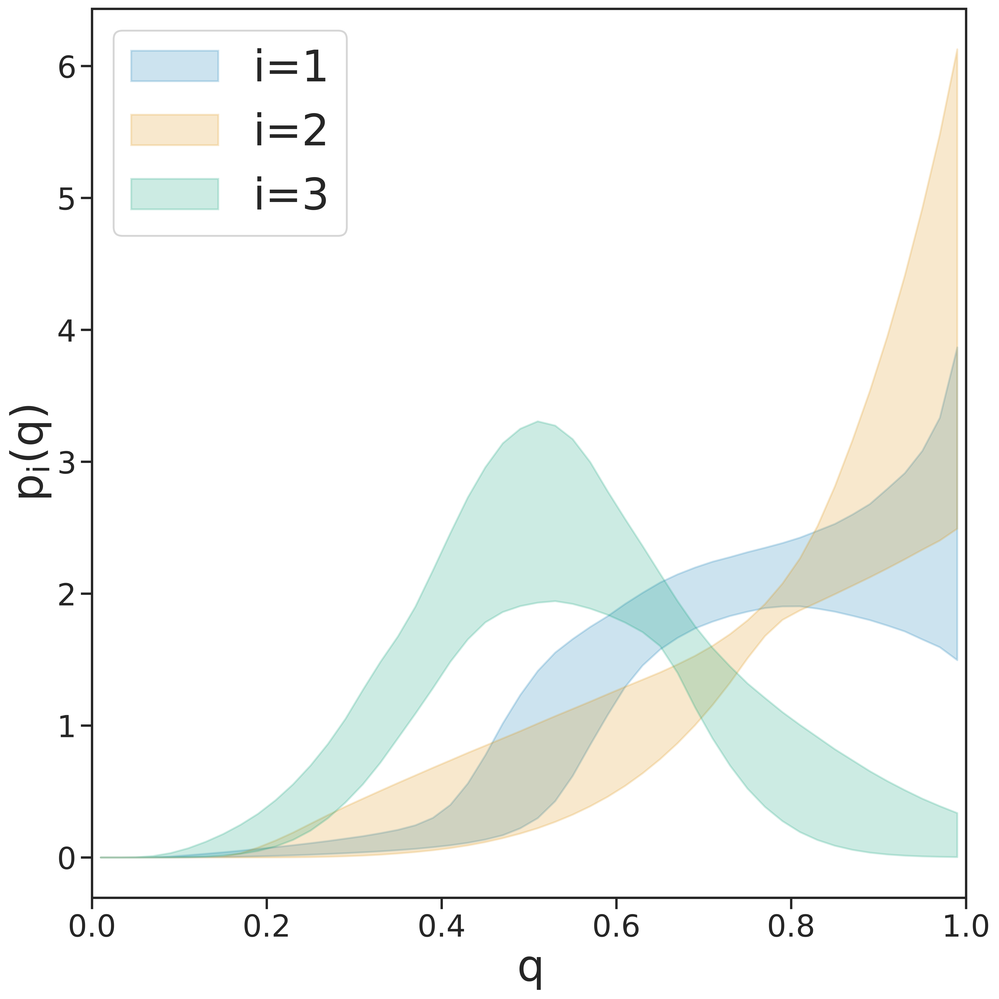

In [129]:
%matplotlib inline
plt.clf()
fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})
for i,comp in enumerate(["1", "2", "3"]):
    p_chieff = np.array(subpops[comp]["q"])
    p_chieff/= (np.trapz(p_chieff, q_grid, axis = -1)[:,None])
    ax.fill_between(q_grid, np.quantile(p_chieff, 0.05, axis = 0), np.quantile(p_chieff, 0.95, axis = 0), alpha = 0.2, color = colors[i],
                    label = f"i={i+1}", rasterized = True)
    #break
#ax.axvline(0.0, color = "black", ls = "dashed", lw = 2.5)
ax.set_xlabel(r"$q$", fontsize = tfs)
ax.set_ylabel(r"$p_i(q)$", fontsize = tfs)
ax.set_xlim(0,1.0)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
ax.legend(fontsize = tfs)
fig.tight_layout()
fig.savefig(f"{plot_dir}/q.png")
fig.savefig(f"{plot_dir}/q.pdf")

/tmp/ipykernel_157/40097374.py:4: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= (np.trapz(p_chieff, q_grid, axis = -1)[:,None])
100%|██████████| 4970/4970 [00:00<00:00, 25942.19it/s]
/tmp/ipykernel_157/40097374.py:16: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= (np.trapz(p_chieff, q_grid, axis = -1)[:,None])
100%|██████████| 4970/4970 [00:00<00:00, 27555.11it/s]
/tmp/ipykernel_157/40097374.py:26: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= (np.trapz(p_chieff, q_grid, axis = -1)[:,None])
100%|██████████| 4970/4970 [00:00<00:00, 26543.08it/s]


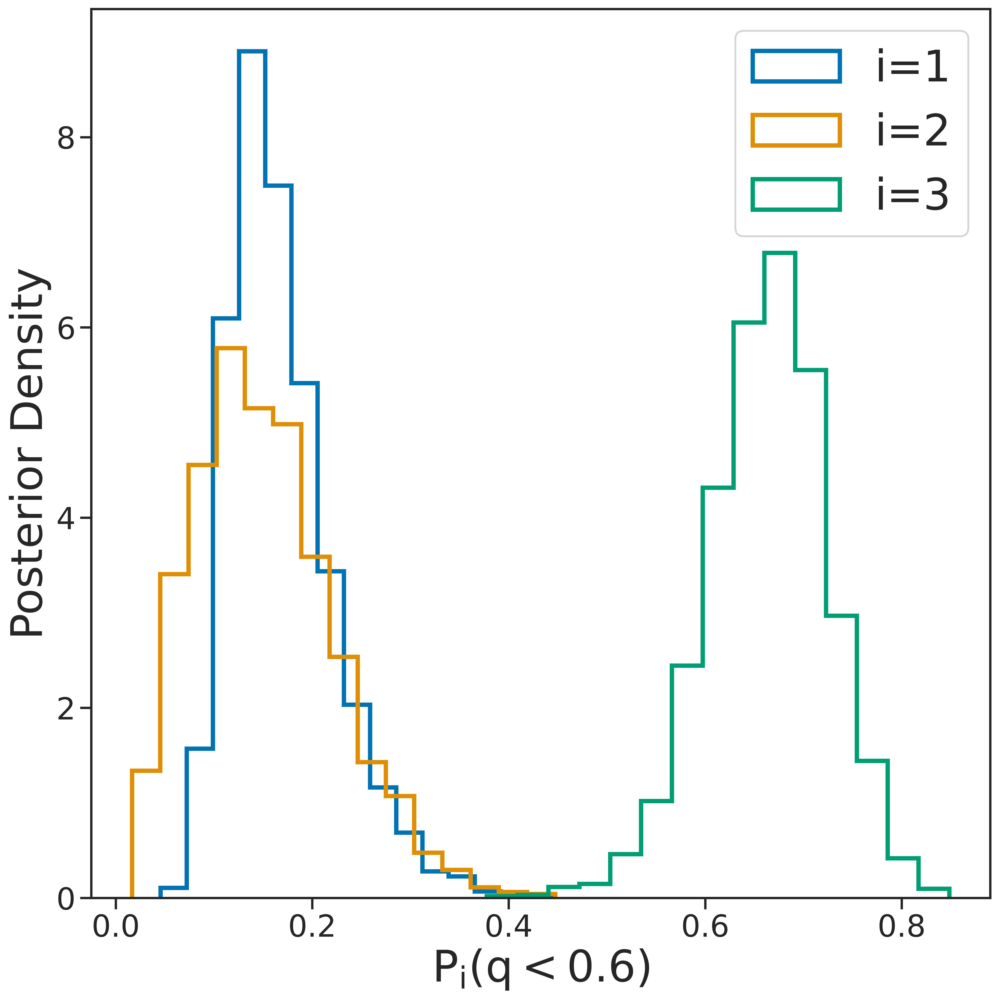

In [130]:
from scipy.integrate import cumulative_trapezoid as cumtrapz
from scipy.interpolate import interp1d
p_chieff = subpops["1"]["q"]
p_chieff/= (np.trapz(p_chieff, q_grid, axis = -1)[:,None])
cdf = cumtrapz(p_chieff, q_grid, axis = -1, initial = 0.0)
cdf/=(cdf[:,-1][:,None])
frac = []
for this_cdf in tqdm.tqdm(cdf):
    inpcdf = interp1d(q_grid, this_cdf)
    frac.append(inpcdf(0.6))
frac_1 = np.array(frac)

from scipy.integrate import cumulative_trapezoid as cumtrapz
from scipy.interpolate import interp1d
p_chieff = subpops["2"]["q"]
p_chieff/= (np.trapz(p_chieff, q_grid, axis = -1)[:,None])
cdf = cumtrapz(p_chieff, q_grid, axis = -1, initial = 0.0)
cdf/=(cdf[:,-1][:,None])
frac = []
for this_cdf in tqdm.tqdm(cdf):
    inpcdf = interp1d(q_grid, this_cdf)
    frac.append(inpcdf(0.6))
frac_2 = np.array(frac)

p_chieff = subpops["3"]["q"]
p_chieff/= (np.trapz(p_chieff, q_grid, axis = -1)[:,None])
cdf = cumtrapz(p_chieff, q_grid, axis = -1, initial = 0.0)
cdf/=(cdf[:,-1][:,None])
frac = []
for this_cdf in tqdm.tqdm(cdf):
    inpcdf = interp1d(q_grid, this_cdf)
    frac.append(inpcdf(0.6))
frac_3 = np.array(frac)

fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})
nbins = 15
_ = ax.hist(frac_1, histtype = "step", label = "i=1", density = True, lw=hist_lw, rasterized = True, bins = nbins)
_ = ax.hist(frac_2, histtype = "step", label = "i=2", density = True, lw=hist_lw, rasterized = True, bins = nbins)
_ = ax.hist(frac_3, histtype = "step", label = "i=3", density = True, lw=hist_lw, rasterized = True, bins = nbins)
ax.set_xlabel(r"$P_i(q<0.6)$", fontsize = tfs)
ax.set_ylabel("Posterior Density", fontsize = tfs)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
#ax.axvline(0.5, color = "black", ls ="dashed", lw = 2.5)
ax.legend(fontsize = tfs)
# ax.semilogy()
# ax.set_ylim(1e-1,1e3)
fig.tight_layout()
fig.savefig(f"{plot_dir}/q_99.png")
fig.savefig(f"{plot_dir}/q_99.pdf")

<Figure size 640x480 with 0 Axes>

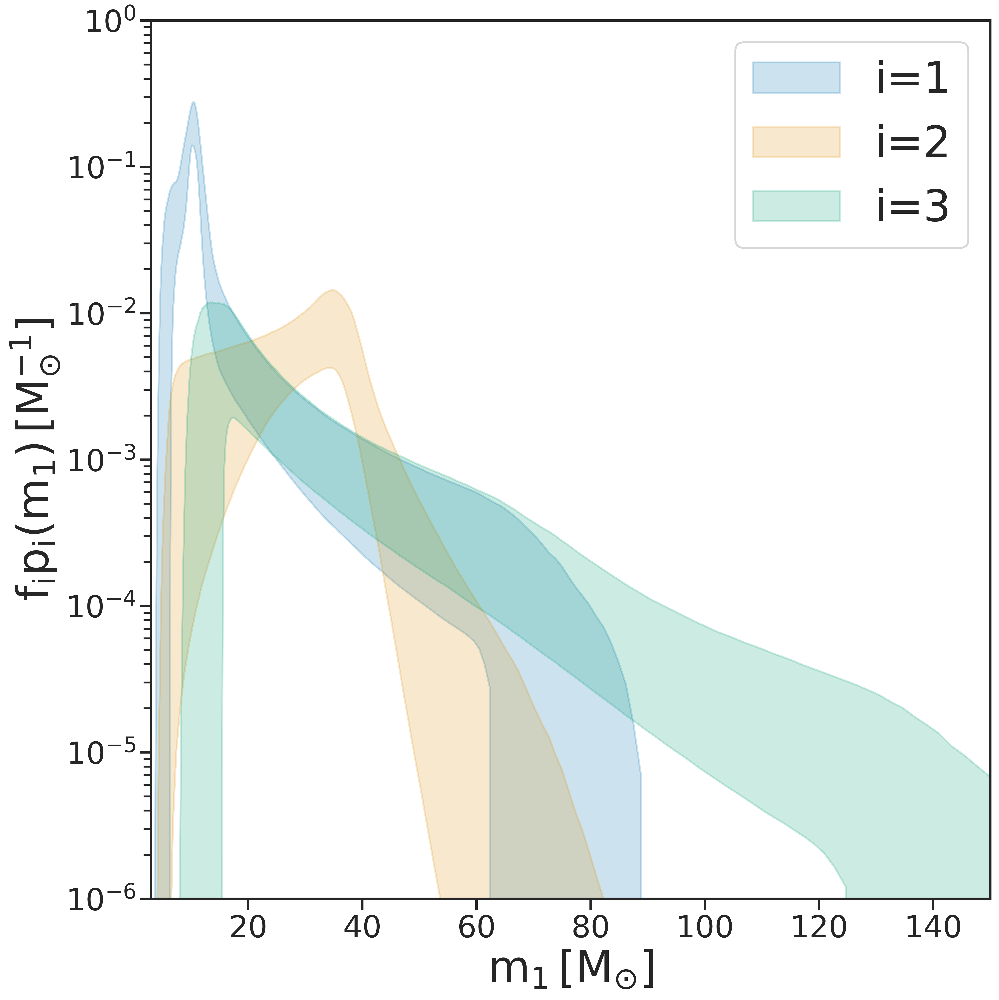

In [131]:
%matplotlib inline
plt.clf()
fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})
for i,comp in enumerate(["1", "2", "3"]):
    
    p_chieff = np.array(subpops[comp]["m1"])
    #p_chieff/= (np.trapz(p_chieff, q_grid, axis = -1)[:,None])
    ax.fill_between(m1_grid, np.quantile(p_chieff, 0.05, axis = 0), np.quantile(p_chieff, 0.95, axis = 0), alpha = 0.2, color = colors[i],
                    label = f"i={i+1}", rasterized = True)
    #break
ax.set_xlabel(r"$m_1\,[M_{\odot}]$", fontsize = tfs)
ax.set_ylabel(r"$f_ip_i(m_1)\,[M_{\odot}^{-1}]$", fontsize = tfs)
ax.semilogy()
ax.set_xlim(3,150)
ax.set_ylim(1e-6,1)
ax.legend(fontsize = tfs)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
fig.tight_layout()
fig.savefig(f"{plot_dir}/m1.png")
fig.savefig(f"{plot_dir}/m1.pdf")
plt.show()

In [41]:
%matplotlib inline
plt.clf()
fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(28, 12))
tfs = fs * 0.5
tfs2 = fs
matplotlib.rcParams.update({'font.size': tfs})
for i,comp in enumerate(["1", "2", "3"]):
    
    p_chieff = np.array(subpops[comp]["m1"])
    #p_chieff/= (np.trapz(p_chieff, q_grid, axis = -1)[:,None])
    ax.fill_between(m1_grid, np.quantile(p_chieff, 0.05, axis = 0), np.quantile(p_chieff, 0.95, axis = 0), alpha = 0.2, color = colors[i],
                    label = f"i={i+1}", rasterized = True)
    #break
ax.set_xlabel(r"$m_1\,[M_{\odot}]$", fontsize = tfs2)
ax.set_ylabel(r"$f_ip_i(m_1)\,[M_{\odot}^{-1}]$", fontsize = tfs2)
ax.semilogy()
ax.set_xlim(3,150)
ax.set_ylim(1e-6,1)
ax.legend(fontsize = tfs)
ax.tick_params(axis='y', which='major', labelsize=tfs2*0.7)
ax.tick_params(axis='y', which='minor', labelsize=tfs2*0.7)
ax.tick_params(axis='x', which='major', labelsize=tfs2*0.7)
ax.tick_params(axis='x', which='minor', labelsize=tfs2*0.7)
fig.tight_layout()
fig.savefig(f"{plot_dir}/m1_diffsize.png")
fig.savefig(f"{plot_dir}/m1_diffsize.pdf")
plt.show()

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

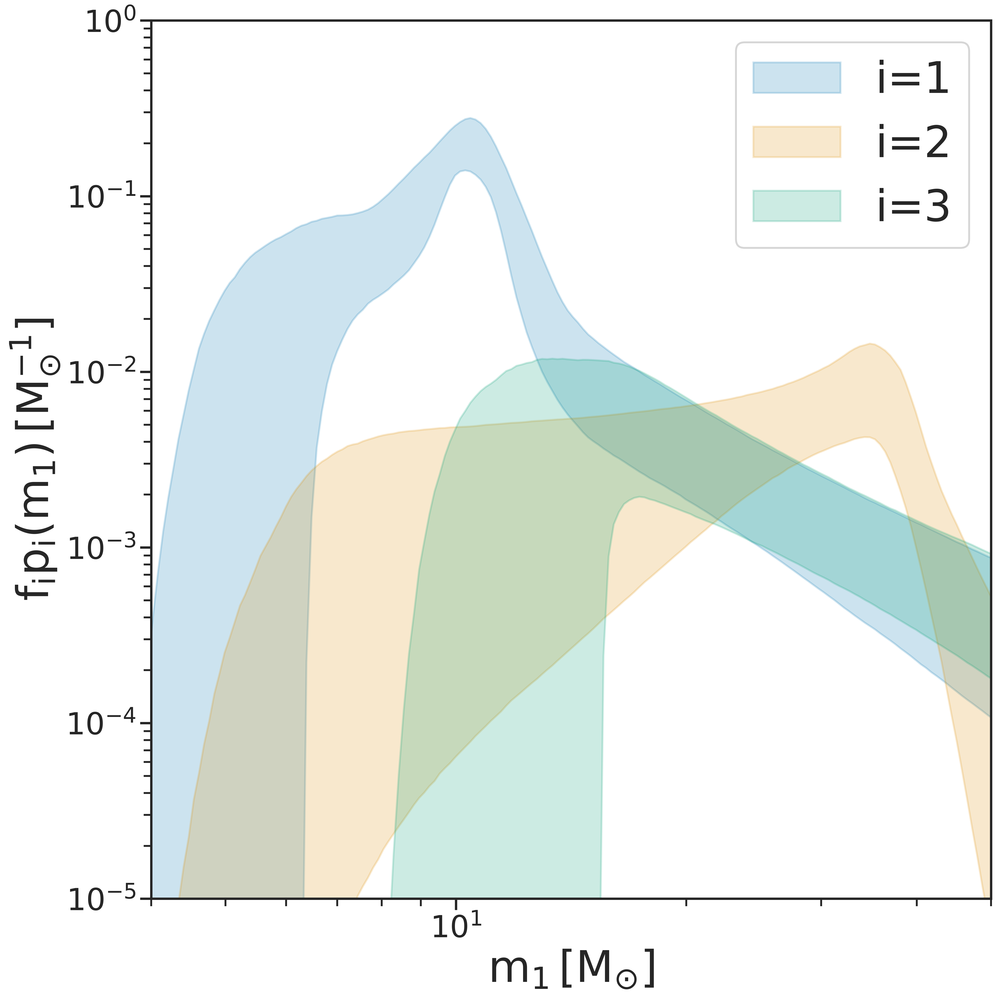

In [132]:
%matplotlib inline
plt.clf()
fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})
for i,comp in enumerate(["1", "2", "3"]):
    
    p_chieff = np.array(subpops[comp]["m1"])
    #p_chieff/= (np.trapz(p_chieff, q_grid, axis = -1)[:,None])
    ax.fill_between(m1_grid, np.quantile(p_chieff, 0.05, axis = 0), np.quantile(p_chieff, 0.95, axis = 0), alpha = 0.2, color = colors[i],
                    label = f"i={i+1}", rasterized = True)
    #break
ax.set_xlabel(r"$m_1\,[M_{\odot}]$", fontsize = tfs)
ax.set_ylabel(r"$f_ip_i(m_1)\,[M_{\odot}^{-1}]$", fontsize = tfs)
ax.loglog()
ax.set_xlim(4,50)
ax.set_ylim(1e-5,1)
ax.legend(fontsize = tfs)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
fig.tight_layout()
fig.savefig(f"{plot_dir}/m1_loglog.png")
fig.savefig(f"{plot_dir}/m1_loglog.pdf")
plt.show()

In [54]:
from gwpopulation import vt
from models import three_component_mixture_3_restricted_z as mixture_model
from gwpopulation.experimental.jax import JittedLikelihood, NonCachingModel
import pandas as pd
import dill

try:
    R_0 = np.loadtxt(f"{plot_dir}/R0.txt")
except:
    posteriors = pd.read_pickle("data/posteriors.pkl")
    
    with open("data/injections.pkl", "rb") as ff:
        injections = dill.load(ff)
    
    
    
    model = NonCachingModel(
        model_functions=[
            mixture_model,
            #PowerLawRedshift(cosmo_model="Planck15"),
        ],
    )
    
    VT = vt.ResamplingVT(model=model, data=injections, n_events=len(posteriors))
    from gwpopulation_pipe.data_analysis import compute_rate_posterior
    from gwpopulation_pipe import vt_helper
    
    vt_helper.N_EVENTS = len(posteriors)
    compute_rate_posterior(posterior, VT)
    np.savetxt(f"{plot_dir}/R0.txt", 10.0**posterior["log_10_rate"])
    R_0 = 10.0**posterior["log_10_rate"]

    


In [55]:
R_z = {"1":[], "2":[], "3":[]}
from models import differential_hypervolume
vol_denom = differential_hypervolume(0.0)
R0 = []
for i in tqdm.tqdm(range(Nsamp)):
    vol = sum(ws[comp][i,0]*differential_hypervolume( posterior[f"lamb_{int(comp)}"].to_numpy()[i]) for comp in R_z.keys())
    #R_0 = 10.0**(posterior["log_10_rate"].to_numpy()[i]) * vol_denom / vol 
    R0.append(R_0[i]*vol_denom/vol)
    for comp in R_z.keys():
        R_z[comp].append(ws[comp][i,0] * R0[i] * (1.0+z_grid)**(posterior[f"lamb_{int(comp)}"].to_numpy()[i]) )
              

100%|██████████| 4613/4613 [00:04<00:00, 1088.89it/s]


<Figure size 640x480 with 0 Axes>

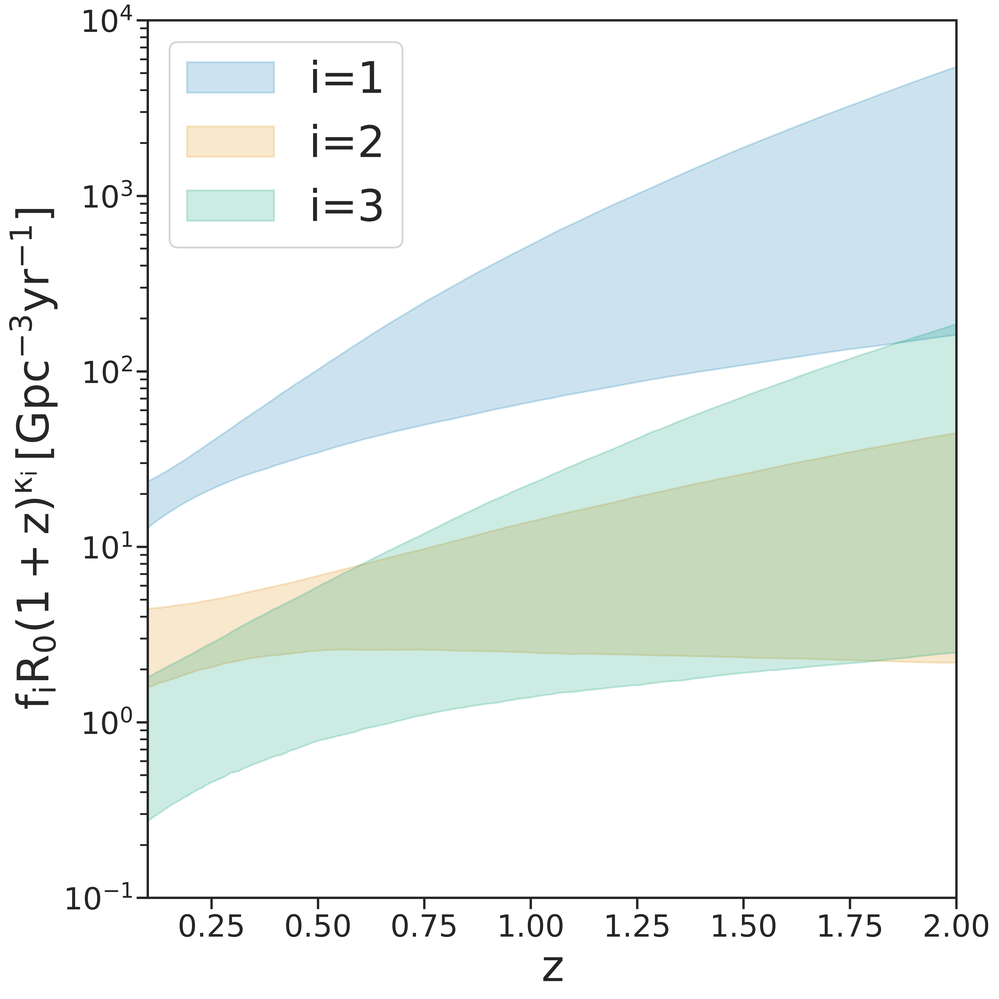

In [56]:
%matplotlib inline
plt.clf()
fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})
for i,comp in enumerate(["1", "2", "3"]):
    
    p_chieff = R_z[comp]#np.array(subpops[comp]["z"])
    #p_chieff/= (np.trapz(p_chieff, q_grid, axis = -1)[:,None])
    ax.fill_between(z_grid, np.quantile(p_chieff, 0.05, axis = 0), np.quantile(p_chieff, 0.95, axis = 0), alpha = 0.2, color = colors[i],
                    label = f"i={i+1}", rasterized=True)
    #break
ax.set_xlabel(r"$z$", fontsize = tfs)
ax.set_ylabel(r"$f_iR_0(1+z)^{\kappa_i}\,[Gpc^{-3}yr^{-1}]$", fontsize = tfs)
ax.legend(fontsize = tfs)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
ax.semilogy()
ax.set_ylim(1e-1,1e4)
ax.set_xlim(0.1, 2)

fig.tight_layout()
fig.savefig(f"{plot_dir}/R_z.png")
fig.savefig(f"{plot_dir}/R_z.pdf")
plt.show()

<Figure size 640x480 with 0 Axes>

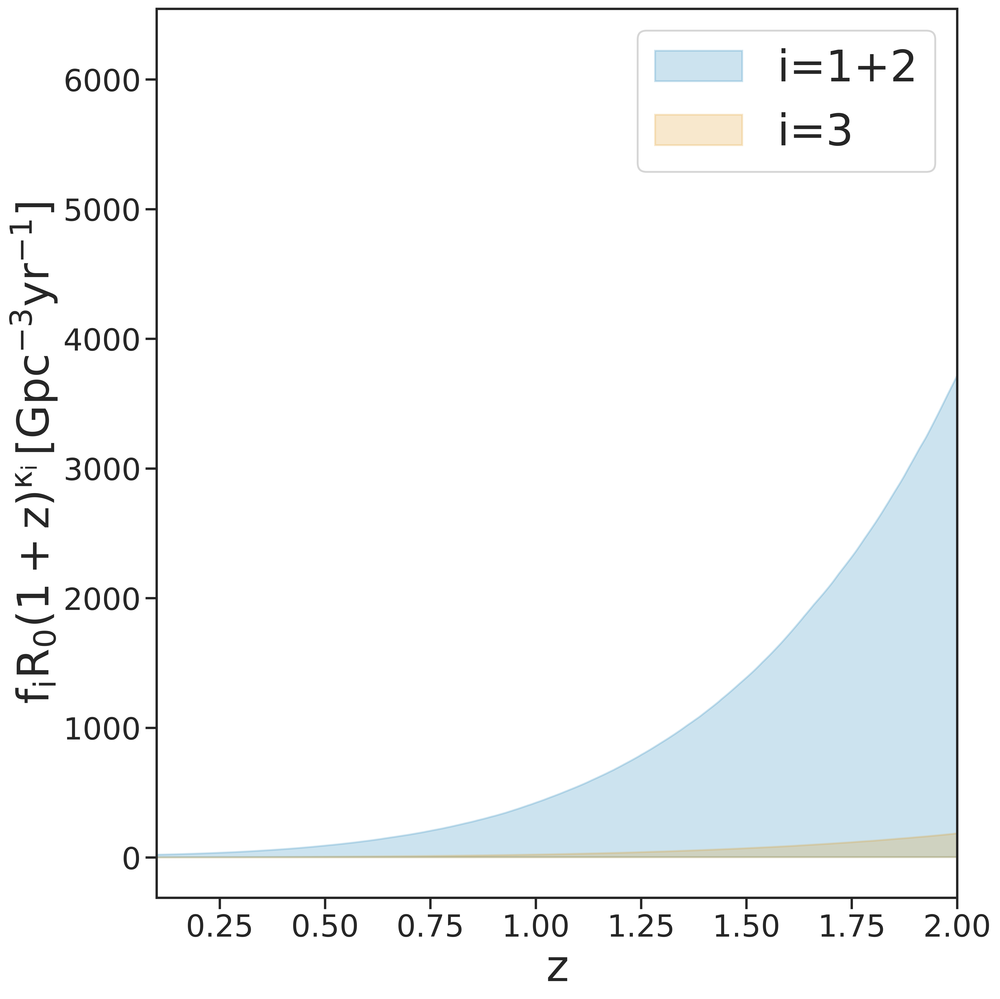

In [58]:
%matplotlib inline
plt.clf()
fig, ax = plt.subplots(1,dpi = 500, tight_layout = True, figsize=(12,12))
tfs = fs * 0.5
matplotlib.rcParams.update({'font.size': tfs})
labels = ["1+2", "3"]
for i,comp in enumerate(["1", "3"]):
    if comp=="1":
        p_chieff = R_z["1"]+R_z["2"]#np.array(subpops[comp]["z"])
    else:
        p_chieff = R_z[comp]
    #p_chieff/= (np.trapz(p_chieff, q_grid, axis = -1)[:,None])
    ax.fill_between(z_grid, np.quantile(p_chieff, 0.05, axis = 0), np.quantile(p_chieff, 0.95, axis = 0), alpha = 0.2, color = colors[i],
                    label = f"i={labels[i]}", rasterized=True)
    #break
ax.set_xlabel(r"$z$", fontsize = tfs)
ax.set_ylabel(r"$f_iR_0(1+z)^{\kappa_i}\,[Gpc^{-3}yr^{-1}]$", fontsize = tfs)
ax.legend(fontsize = tfs)
ax.tick_params(axis='both', which='major', labelsize=tfs*0.7)
ax.tick_params(axis='both', which='minor', labelsize=tfs*0.7)
#ax.semilogy()
#ax.set_ylim(1e-1,1e4)
ax.set_xlim(0.1, 2)

fig.tight_layout()
fig.savefig(f"{plot_dir}/R_z12_vs_3.png")
fig.savefig(f"{plot_dir}/R_z12_vs_3.pdf")
plt.show()

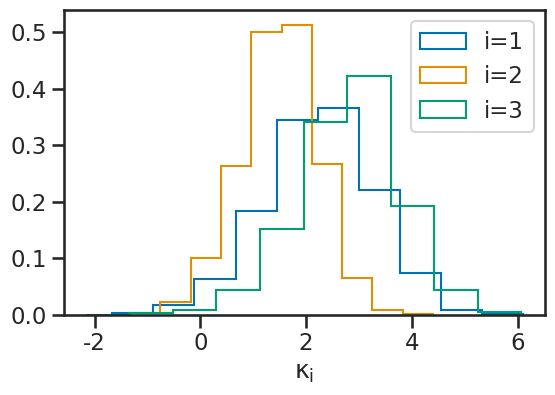

In [36]:
for i,comp in enumerate(["1", "2", "3"]):
    _=plt.hist(posterior[f"lamb_{comp}"].to_numpy(), histtype = "step", density = True, label = f"i={comp}")
plt.xlabel(r"$\kappa_i$")
plt.legend()
plt.tight_layout()
plt.savefig(f"{plot_dir}/kappas.png")

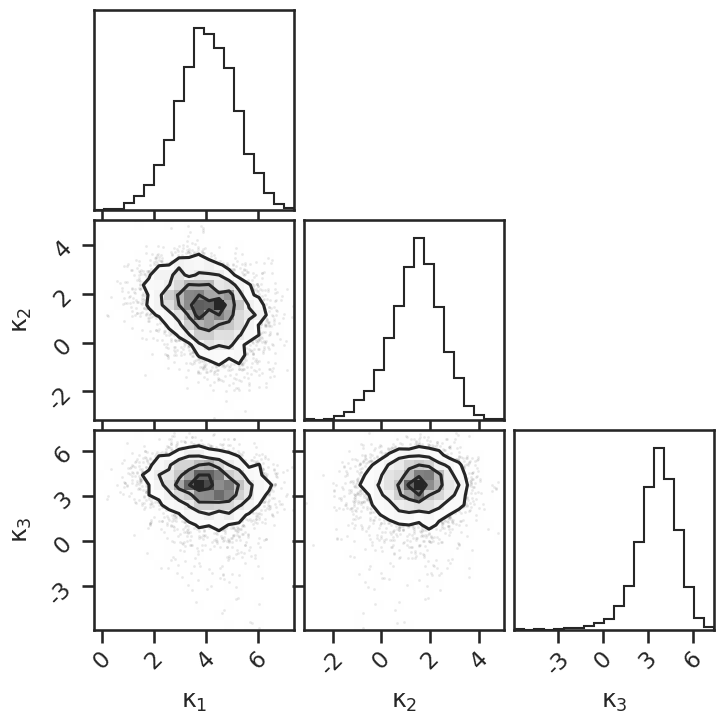

In [43]:
import corner
fig = corner.corner(posterior[["lamb_1", "lamb_2", "lamb_3"]].to_numpy(), labels = [r"$\kappa_1$", r"$\kappa_2$", r"$\kappa_3$"],
                   ranges=[(-2,7) for i in range(3)])
fig.savefig("plots/kappas.png")

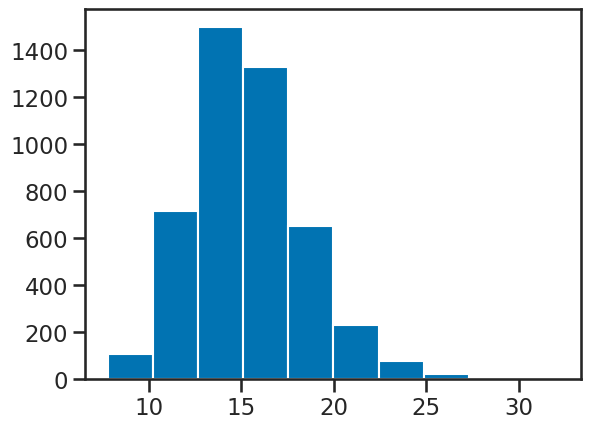

In [44]:
_=plt.hist(R0)

### Transition

In [37]:
m1I = (m1_grid>=10.0) * (m1_grid <=35)
m1II = (m1_grid>=35.0) * (m1_grid <=52)
mtI = [ ]
mtII = [ ]
for i in tqdm.tqdm(range(Nsamp)):
    p_1 = subpops["1"]["m1"][i]#,:]
    p_2 = subpops["2"]["m1"][i]#,:]
    p_3 = subpops["3"]["m1"][i]#,:]
    #print(p_2.shape, p_3.shape)
    p_23 = np.maximum(p_2, p_3)
    p_13 = np.maximum(p_1, p_3)
    diffI = abs(p_1 - p_23)
    #diffI*=m1I
    diffI = diffI.at[~m1I].set(1e10)
    mtI.append(m1_grid[np.argmin(diffI)])
    diffII = abs(p_2 - p_13)
    #diffI*=m1I
    diffII = diffII.at[~m1II].set(1e10)
    mtII.append(m1_grid[np.argmin(diffII)])
    

100%|██████████| 4970/4970 [00:07<00:00, 635.47it/s]


In [38]:
mtI = np.array(mtI)
mtII = np.array(mtII)

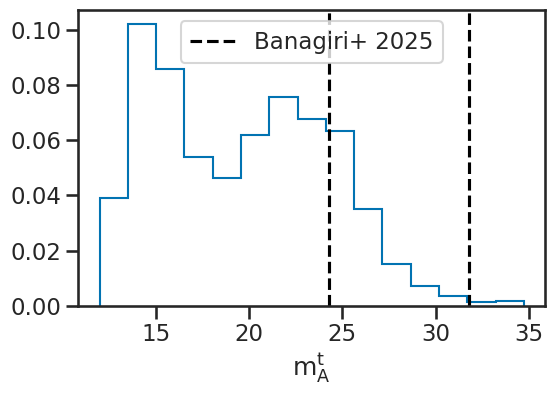

In [39]:
_=plt.hist(mtI, density = True, histtype = "step", bins=15)
plt.xlabel(r"$m^t_{A}$")
plt.axvline(27.7+4.1, color = "black", ls = "dashed", label = "Banagiri+ 2025")
plt.axvline(27.7-3.4, color = "black", ls = "dashed")#, label = "Banagiri+ 2025")
plt.legend()
plt.tight_layout()
plt.savefig(f"{plot_dir}/mtA.png")

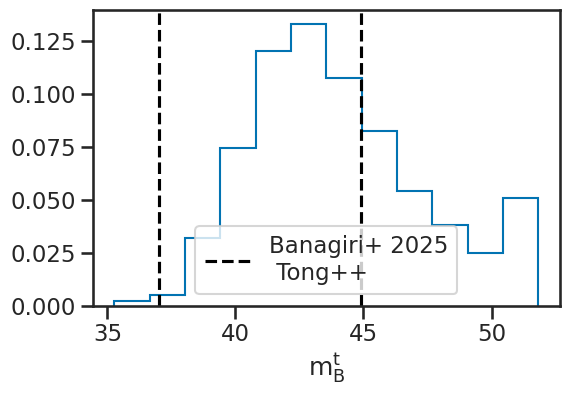

In [40]:
_=plt.hist(mtII, density = True, histtype = "step", bins=12)
plt.xlabel(r"$m^t_{B}$")
plt.axvline(40.2+4.7, color = "black", ls = "dashed", label = "Banagiri+ 2025\n Tong++")
plt.axvline(40.2-3.2, color = "black", ls = "dashed")#, label = "Banagiri+ 2025")
plt.legend()
plt.tight_layout()
plt.savefig("plots/mtB.png")

In [59]:
pm1_marg = sum(np.array(subpops[comp]["m1"]) for comp in subpops.keys())
pm1_marg.shape

(4613, 300)

In [62]:
weights = {"I":[], "II":[], "III":[]}
for i,(this_mtI, this_mtII) in enumerate(zip(tqdm.tqdm(mtI),mtII)):
    arg1 = (m1_grid <= this_mtI)
    arg2 = (m1_grid >= this_mtI)  * (m1_grid <= this_mtII)
    arg3 = (m1_grid >= this_mtII) * (m1_grid <=posterior["mmax1"].to_numpy()[i])
    args = {"I":arg1, "II":arg2, "III": arg3}
    #weight = {}#"I":[], "II":[], "III":[]}
    for key in args.keys():
        this_weight = []
        weight_denom = np.trapz(pm1_marg[i] * args[key], m1_grid)
        for comp in ["1", "2", "3"]:
            p_m = subpops[comp]["m1"][i]
            this_weight.append(np.trapz(p_m * args[key], m1_grid)/weight_denom)
        weights[key].append(this_weight)

        
        
    
    
    

  0%|          | 0/4613 [00:00<?, ?it/s]/tmp/ipykernel_283/3412069149.py:10: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  weight_denom = np.trapz(pm1_marg[i] * args[key], m1_grid)
/tmp/ipykernel_283/3412069149.py:13: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  this_weight.append(np.trapz(p_m * args[key], m1_grid)/weight_denom)
100%|██████████| 4613/4613 [00:02<00:00, 2178.41it/s]


In [63]:
weights = {key:np.array(weight) for key, weight in weights.items()}


In [66]:
weights_norm = {key: weight/(np.sum(weight, axis = -1)[:,None]) for key, 
                weight in weights.items()}

In [78]:
p_qs = {"I":[], "II":[], "III":[]}
for i,(this_mtI, this_mtII) in enumerate(zip(tqdm.tqdm(mtI),mtII)):
    arg1 = (m1_grid <= this_mtI)
    arg2 = (m1_grid >= this_mtI)  * (m1_grid <= this_mtII)
    arg3 = (m1_grid >= this_mtII) * (m1_grid <=posterior["mmax1"].to_numpy()[i])
    args = {"I":arg1, "II":arg2, "III": arg3}
    #weight = {}#"I":[], "II":[], "III":[]}
    for key in args.keys():
        this_pq = []
        
        for comp in ["1", "2", "3"]:
            p_m1q = np.array(copy.deepcopy(subpops_2d[comp][i]))
            p_m1q[:,~arg1]=0.0
            p_q = np.trapz(p_m1q, m1_grid, axis=-1)
            this_pq.append(ws[comp][i,0] * p_q/np.trapz(p_q,q_grid))
        
        p_qs[key].append(sum(this_pq))

        
        
    
    
    

  0%|          | 0/4613 [00:00<?, ?it/s]/tmp/ipykernel_283/4213943760.py:14: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_q = np.trapz(p_m1q, m1_grid, axis=-1)
/tmp/ipykernel_283/4213943760.py:15: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  this_pq.append(ws[comp][i,0] * p_q/np.trapz(p_q,q_grid))
/tmp/ipykernel_283/4213943760.py:15: RuntimeWarning: invalid value encountered in divide
  this_pq.append(ws[comp][i,0] * p_q/np.trapz(p_q,q_grid))
100%|██████████| 4613/4613 [00:08<00:00, 574.48it/s]


In [79]:
import h5py
with h5py.File("/home/anarya.ray/noPISN/repo/nopisn/plots/result/temp_m1q_2g.h5", "r") as hf:
    m1 =hf["m1"][()]
    q =hf["q"][()]
    # m1_grid =hf["m1_grid"][()]
    # q_grid =hf["q_grid"][()]
    # p_m1qs1 = hf["p_m1qs1"][()]
    p_m1qs2 = hf["p_m1qs2"][()]
p_qs2 = np.trapz(p_m1qs2, m1, axis =1)
p_qs2/=np.trapz(p_qs2, q,axis=-1)[:,None]
print(p_qs2.shape, q.shape)

/tmp/ipykernel_283/1817019301.py:9: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_qs2 = np.trapz(p_m1qs2, m1, axis =1)


(5882, 50) (50,)


/tmp/ipykernel_283/1817019301.py:10: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_qs2/=np.trapz(p_qs2, q,axis=-1)[:,None]


/tmp/ipykernel_283/3545305908.py:8: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= (np.trapz(p_chieff, q_grid, axis = -1)[:,None])
/tmp/ipykernel_283/3545305908.py:11: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pdf/= (np.trapz(pdf, q_grid)[:,None])


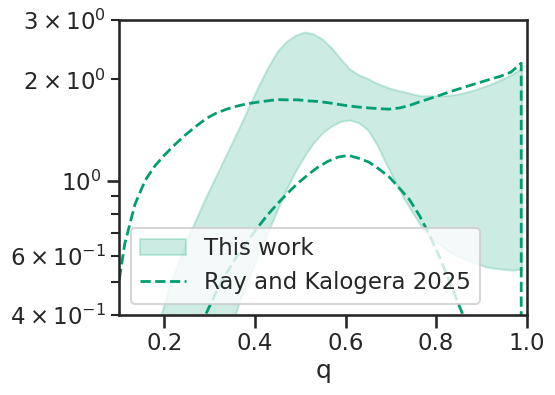

In [80]:
reg = "III"
%matplotlib inline
plt.clf()
pdf = np.zeros((Nsamp, len(q_grid)))
for i,comp in enumerate(["1", "2", "3"]):
    
    p_chieff = np.array(subpops[comp]["q"])
    p_chieff/= (np.trapz(p_chieff, q_grid, axis = -1)[:,None])
    pdf+= p_chieff * (weights_norm[reg][:,:,None][:,i,:])

pdf/= (np.trapz(pdf, q_grid)[:,None])
plt.fill_between(q_grid, np.quantile(pdf, 0.05, axis = 0), np.quantile(pdf, 0.95, axis = 0),
                 alpha = 0.2, color = colors[2], label = "This work"
         )
plt.plot(q, np.quantile(p_qs2, 0.05, axis = 0), ls = "dashed", lw = 2.0, color = colors[2], 
         label = "Ray and Kalogera 2025")
plt.plot(q, np.quantile(p_qs2, 0.95, axis = 0), ls = "dashed", lw = 2.0, color = colors[2])
plt.semilogy()
plt.ylim(0.4, 3.0)
    #break
plt.xlim(0.1,1.0)
plt.xlabel(r"$q$")
plt.legend()
plt.tight_layout()
plt.savefig("plots/q_transIII.png")
plt.show()

### Generate Macros

In [23]:
from scipy.stats import gaussian_kde
def hpd(samples,alpha = 0.1):
    x=np.sort(np.copy(samples))
    n = len(x)
    cred_mass = 1.0-alpha

    interval_idx_inc = int(np.floor(cred_mass*n))
    n_intervals = n - interval_idx_inc
    interval_width = x[interval_idx_inc:] - x[:n_intervals]

    if len(interval_width) == 0:
        raise ValueError('Too few elements for interval calculation')

    min_idx = np.argmin(interval_width)
    hdi_min = x[min_idx]
    hdi_max = x[min_idx+interval_idx_inc]

    return [hdi_min, hdi_max]
def mode(samples):
    kde = gaussian_kde(samples)
    grid = np.linspace(samples.min(), samples.max(), 1000)
    pdf = kde(grid)
    return grid[np.argmax(pdf)]

def credible_interval(samples, kind = "eq"):
    if kind == "eq":
        c = np.median(samples)
        l = np.quantile(samples, 0.05)
        u = np.quantile(samples, 0.95)
        ep = u-c
        em = c-l
        return {"central": c, "low": l, "high":u, "plus":ep, "minus":em}
    else:
        c = mode(samples)
        [l,u] = hpd(samples)
        ep = u-c
        em = c-l
        return {"central": c, "low": l, "high":u, "plus":ep, "minus":em}
        

In [75]:
params = {r"$m_{1,min(1, or 2)}$":posterior["mmin1"].to_numpy(),
          r"$m_{2,min(1, or 2)}$":posterior["m2min"].to_numpy(),
          r"$m_{1,min,3}$":posterior["mmin3"].to_numpy(),
          r"$m_{1,max(1, or 2)}$":posterior["mmax1"].to_numpy(),
          r"$m_{1,max,3}$": 2.0 * posterior["mmax1"].to_numpy(),
          r"$f_1$": w_1*100,
          r"$f_2$": w_2*100,
          r"$f_3$": w_3*100,
          r"$R_{0,1}$": np.array(R_z["1"])[:,0],
          r"$R_{0,2}$": np.array(R_z["2"])[:,0],
          r"$R_{0,3}$": np.array(R_z["3"])[:,0],
          r"$m_t^{AB}$":mtI,
          r"$m_t^{BC}$":mtII,
          r"\mu_{pp,1}": posterior["mpp1"].to_numpy(),
          r"m_{b,2}": posterior["break_mass2"].to_numpy(),
          r"m_{b,3}": posterior["break_mass3"].to_numpy(),
          r"$P_1(\chi_{eff}<0)$": frac_1*100,
          r"$P_2(\chi_{eff}<0)$": frac_2*100,
          r"$f_{1,I}$": weights_norm["I"][:,0]*100,
          r"$f_{1,II}$": weights_norm["II"][:,0]*100,
          r"$f_{1,III}$": weights_norm["III"][:,0]*100,
          r"$f_{2,I}$": weights_norm["I"][:,1]*100,
          r"$f_{2,II}$": weights_norm["II"][:,1]*100,
          r"$f_{2,III}$": weights_norm["III"][:,1]*100,
          r"$f_{3,I}$": weights_norm["I"][:,2]*100,
          r"$f_{3,II}$": weights_norm["II"][:,2]*100,
          r"$f_{3,III}$": weights_norm["III"][:,2]*100,
          
         }

In [76]:
with open("plots/macros.txt", "w") as tf:
    for key,samples in params.items():
        intervals = credible_interval(samples, kind = "hpd")
        print(key[:-1]+f"={intervals['central']:.2f}"+"^{+"+f"{intervals['plus']:.2f}"+"}_{-"+f"{intervals['minus']:.2f}"+"}$")
        tf.write(key[:-1]+f"={intervals['central']:.2f}"+"^{+"+f"{intervals['plus']:.2f}"+"}_{-"+f"{intervals['minus']:.2f}"+"}$")
        tf.write("\n")

$m_{1,min(1, or 2)}=6.93^{+2.19}_{-2.43}$
$m_{2,min(1, or 2)}=4.78^{+0.98}_{-0.90}$
$m_{1,min,3}=12.72^{+5.13}_{-6.52}$
$m_{1,max(1, or 2)}=69.98^{+21.71}_{-7.50}$
$m_{1,max,3}=139.96^{+43.42}_{-15.00}$
$f_1=78.99^{+11.55}_{-10.91}$
$f_2=14.47^{+11.59}_{-7.97}$
$f_3=2.50^{+5.48}_{-1.84}$
$R_{0,1}=11.33^{+5.27}_{-4.05}$
$R_{0,2}=2.17^{+1.84}_{-1.08}$
$R_{0,3}=0.42^{+0.76}_{-0.32}$
$m_t^{AB}=23.33^{+4.23}_{-7.00}$
$m_t^{BC}=41.82^{+5.44}_{-4.31}$
\mu_{pp,1=9.77^{+0.92}_{-4.14}$
m_{b,2=36.12^{+2.08}_{-2.51}$
m_{b,3=58.60^{+15.78}_{-24.35}$
$P_1(\chi_{eff}<0)=22.95^{+12.92}_{-10.26}$
$P_2(\chi_{eff}<0)=51.68^{+16.14}_{-17.07}$
$f_{1,I}=96.33^{+1.83}_{-5.03}$
$f_{1,II}=16.29^{+11.87}_{-8.29}$
$f_{1,III}=45.39^{+26.88}_{-37.73}$
$f_{2,I}=2.49^{+4.02}_{-1.24}$
$f_{2,II}=74.75^{+10.79}_{-14.01}$
$f_{2,III}=9.06^{+10.08}_{-4.32}$
$f_{3,I}=0.34^{+3.67}_{-0.34}$
$f_{3,II}=5.76^{+11.59}_{-4.76}$
$f_{3,III}=51.62^{+28.99}_{-37.11}$


/tmp/ipykernel_160/2768457696.py:8: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= (np.trapz(p_chieff, q_grid, axis = -1)[:,None])
/tmp/ipykernel_160/2768457696.py:11: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pdf/= (np.trapz(pdf, q_grid)[:,None])


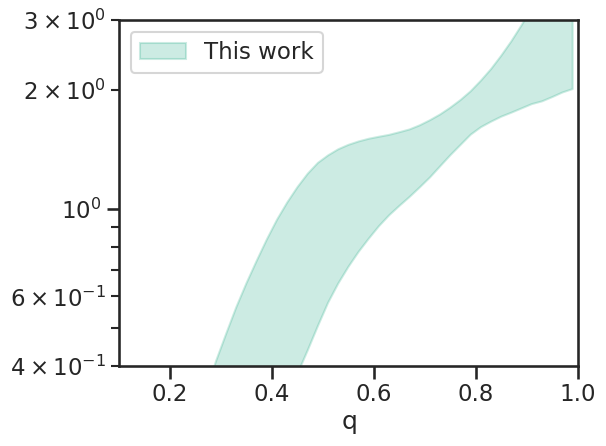

In [93]:
# reg = "II"
# %matplotlib inline
# plt.clf()
# pdf = np.zeros((Nsamp, len(q_grid)))
# for i,comp in enumerate(["1", "2", "3"]):
    
#     p_chieff = np.array(subpops[comp]["q"])
#     p_chieff/= (np.trapz(p_chieff, q_grid, axis = -1)[:,None])
#     pdf+= p_chieff * (weights_norm[reg][:,:,None][:,i,:])

# pdf/= (np.trapz(pdf, q_grid)[:,None])
# plt.fill_between(q_grid, np.quantile(pdf, 0.05, axis = 0), np.quantile(pdf, 0.95, axis = 0),
#                  alpha = 0.2, color = colors[2], label = "This work"
#          )
# # plt.plot(q, np.quantile(p_qs2, 0.05, axis = 0), ls = "dashed", lw = 2.0, color = colors[2], 
# #          label = "Ray and Kalogera 2025")
# # plt.plot(q, np.quantile(p_qs2, 0.95, axis = 0), ls = "dashed", lw = 2.0, color = colors[2])
# plt.semilogy()
# plt.ylim(0.4, 3.0)
#     #break
# plt.xlim(0.1,1.0)
# plt.xlabel(r"$q$")
# plt.legend()
# plt.tight_layout()
# plt.savefig("plots/q_transIII.png")
# plt.show()

In [46]:
import h5py
with h5py.File("/home/anarya.ray/noPISN/repo/nopisn/plots/result/temp_chieff_chip_2g.h5", "r") as hf:
    chi_eff = hf["chi_eff"][()]
    chi_p = hf["chi_p"][()]
    #chi_eff_grid = hf["chi_eff_grid"][()]
    #chi_p_grid = hf["chi_p_grid"][()]
    #p_chieff_1 = hf["p_chieff_1"][()]
    #p_chip_1 = hf["p_chip_1"][()]
    p_chieff_2 = hf["p_chieff_2"][()]
    p_chip_2 = hf["p_chip_2"][()]
    

/tmp/ipykernel_1599/742830283.py:8: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= (np.trapz(p_chieff, chieff_grid, axis = -1)[:,None])
/tmp/ipykernel_1599/742830283.py:11: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pdf/= (np.trapz(pdf, chieff_grid)[:,None])


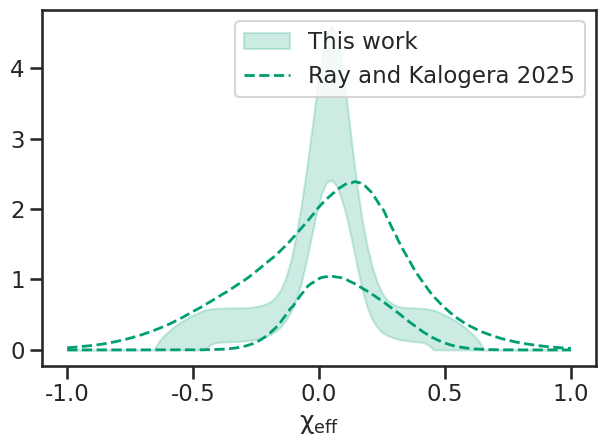

In [47]:
reg = "III"
%matplotlib inline
plt.clf()
pdf = np.zeros((Nsamp, len(chieff_grid)))
for i,comp in enumerate(["1", "2", "3"]):
    
    p_chieff = np.array(subpops[comp]["chieff"])
    p_chieff/= (np.trapz(p_chieff, chieff_grid, axis = -1)[:,None])
    pdf+= p_chieff * (weights_norm[reg][:,:,None][:,i,:])

pdf/= (np.trapz(pdf, chieff_grid)[:,None])
plt.fill_between(chieff_grid, np.quantile(pdf, 0.05, axis = 0), 
                 np.quantile(pdf, 0.95, axis = 0), alpha = 0.2, color = colors[2], 
                 label = "This work"
         )
plt.plot(chi_eff, np.quantile(p_chieff_2, 0.05, axis = 0), ls = "dashed", lw = 2.0, color = colors[2], 
         label = "Ray and Kalogera 2025")
plt.plot(chi_eff, np.quantile(p_chieff_2, 0.95, axis = 0), ls = "dashed", lw = 2.0, color = colors[2])
#plt.semilogy()
# plt.semilogy()
# plt.ylim(0.4, 3.0)
#     #break
plt.xlabel(r"$\chi_{eff}$")
plt.legend()
plt.tight_layout()
#plt.savefig("plots/q.png")
plt.show()

/tmp/ipykernel_1599/2172520117.py:8: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  p_chieff/= (np.trapz(p_chieff, chip_grid, axis = -1)[:,None])
/tmp/ipykernel_1599/2172520117.py:11: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  pdf/= (np.trapz(pdf, chip_grid)[:,None])


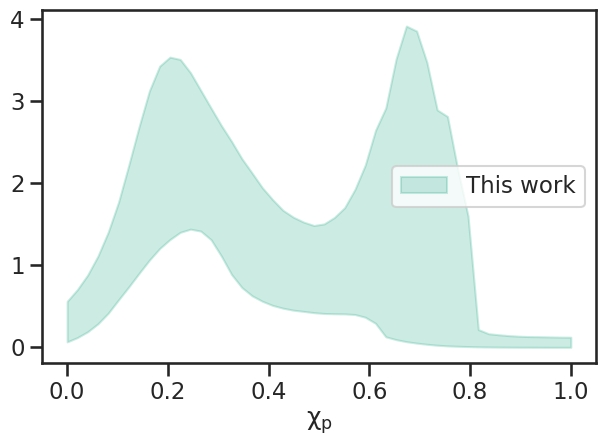

In [51]:
reg = "III"
%matplotlib inline
plt.clf()
pdf = np.zeros((Nsamp, len(chip_grid)))
for i,comp in enumerate(["1", "2", "3"]):
    
    p_chieff = np.array(subpops[comp]["chip"])
    p_chieff/= (np.trapz(p_chieff, chip_grid, axis = -1)[:,None])
    pdf+= p_chieff * (weights_norm[reg][:,:,None][:,i,:])

pdf/= (np.trapz(pdf, chip_grid)[:,None])
plt.fill_between(chip_grid, np.quantile(pdf, 0.05, axis = 0), 
                 np.quantile(pdf, 0.95, axis = 0), alpha = 0.2, color = colors[2], 
                 label = "This work"
         )
# plt.plot(chi_eff, np.quantile(p_chieff_2, 0.05, axis = 0), ls = "dashed", lw = 2.0, color = colors[2], 
#          label = "Ray and Kalogera 2025")
# plt.plot(chi_eff, np.quantile(p_chieff_2, 0.95, axis = 0), ls = "dashed", lw = 2.0, color = colors[2])
#plt.semilogy()
# plt.semilogy()
# plt.ylim(0.4, 3.0)
#     #break
plt.xlabel(r"$\chi_p$")
plt.legend()
plt.tight_layout()
#plt.savefig("plots/q.png")
plt.show()